# Predicting athletes’ best season performances

I study **100H, 400H, 400m, and long jump**. I use two models for each event, with separate charts:

- **Regular model:** predicts time in seconds or jump distance in meters.
- **Log model:** lets me explain year differences as percentages.

Both models use the athlete’s **outdoor eligibility year—first through fourth**. They account for each athlete’s usual performance level and recognize when the same person appears in multiple seasons.

I compare each year with **first year**. My models do not assume athletes improve at the same rate every year.

**Lower times are better for running. Longer distances are better for long jump.**

To use my notebook, **run all cells from the top**. The data are included. GitHub shows still-image charts, while Jupyter lets me hover over points to see athlete details.

I also check **where my models make mistakes**, whether unusual results affect my findings, and how well my models predict later seasons. A low prediction error alone does not mean a model is a good fit.

## How I chose my data

I use **one best result for each athlete in each outdoor season**:

- **Running:** fastest time.
- **Long jump:** longest distance.

I convert times into seconds. For example, **1:01.47 becomes 61.47 seconds**. I leave out fouls, unfinished races, and other results without a valid mark. If best results are tied, I choose one using the meet date and source link.

For 100H, I keep the **705 previously reviewed results**, including the **32.80-second time**. For the other events, I use the results collected in my project. “Season best” means the best result **in my data**, since some meets may be missing. I include wind-assisted results.

I reuse previously checked athlete names and eligibility years when they match. Otherwise, I use the year listed in the source data. **I have not checked all those years against team rosters.** I leave out cases with missing or conflicting information and list them below. I do not guess eligibility from calendar years.

When a checked athlete ID is unavailable, I match results by name. Name changes or people sharing a name can cause mistakes. **My findings for the additional events are preliminary until I finish checking those names and eligibility years.**

In [3]:
# Setup: embedded data and modeling functions. You do not need to edit this cell.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from scipy.stats import norm
from scipy.optimize import minimize_scalar
import io, base64, html, json, zlib

# The exact random-intercept ML routines below are the same specification as 100H.
def design(df):
    years=df['outdoor_eligibility_year'].to_numpy(int)
    return np.column_stack([np.ones(len(df)),*[years==j for j in (2,3,4)]]).astype(float)

def fit_mixed(df, log_time=False):
    """Gaussian random-intercept regression, fitted by profiled maximum likelihood.

    Covariance = residual_variance * I + athlete_variance * Z Z'.
    Uses the exact inverse/determinant of each athlete block (no approximation).
    """
    X=design(df);y=df.best_time_seconds.to_numpy(float)
    if log_time:y=np.log(y)
    ids,g=np.unique(df.athlete_id.astype(str),return_inverse=True)
    counts=np.bincount(g);n=len(y)
    def inverse_apply(A,lam):
        sums=np.zeros((len(ids),A.shape[1]));np.add.at(sums,g,A)
        return A-(lam/(1+lam*counts))[g,None]*sums[g]
    def evaluate(lam,details=False):
        ix=inverse_apply(X,lam);iy=inverse_apply(y[:,None],lam)[:,0]
        information=X.T@ix;beta=np.linalg.solve(information,X.T@iy)
        resid=y-X@beta;rss=float(resid@inverse_apply(resid[:,None],lam)[:,0])
        variance=rss/n
        objective=n*np.log(variance)+np.log1p(lam*counts).sum()
        if details:return beta,variance,np.linalg.inv(information),resid,objective
        return objective
    opt=minimize_scalar(lambda z:evaluate(np.exp(z)),bounds=(-18,18),method='bounded',options={'xatol':1e-10})
    lam=float(np.exp(opt.x))
    if evaluate(0)<=evaluate(lam):lam=0.0
    beta,var,info_inv,resid,obj=evaluate(lam,True)
    sums=np.bincount(g,weights=resid)
    effects=lam*sums/(1+lam*counts)
    posterior=var*lam/(1+lam*counts)
    fit={'beta':beta,'cov_beta':var*info_inv,'residual_variance':var,'athlete_variance':var*lam,
         'lambda':lam,'athlete_effects':dict(zip(ids,effects)),'posterior_variance':dict(zip(ids,posterior)),
         'log_time':log_time,'converged':bool(opt.success),'objective':obj,'n':n,'groups':len(ids)}
    fitted=X@beta+effects[g]
    fit['fitted_scale']=fitted;fit['residuals_scale']=y-fitted
    return fit

def predict_mixed(fit,df,mean=True):
    eta=design(df)@fit['beta']+np.array([fit['athlete_effects'].get(str(a),0.) for a in df.athlete_id])
    if not fit['log_time']:return eta
    if not mean:return np.exp(eta)
    # Expected seconds, integrating future residual and posterior athlete uncertainty.
    pv=np.array([fit['posterior_variance'].get(str(a),fit['athlete_variance']) for a in df.athlete_id])
    return np.exp(eta+0.5*(fit['residual_variance']+pv))

def coefficients(fit):
    b=fit['beta'];se=np.sqrt(np.diag(fit['cov_beta']));lo=b-1.96*se;hi=b+1.96*se
    frame=pd.DataFrame({'term':['First-year intercept','Year 2 vs 1','Year 3 vs 1','Year 4 vs 1'],
      'estimate':b,'standard_error':se,'lower_95':lo,'upper_95':hi,'p_value':2*norm.sf(abs(b/se))})
    if fit['log_time']:
        frame['percent_difference']=100*np.expm1(b);frame.loc[0,'percent_difference']=np.nan
        frame['percent_lower_95']=100*np.expm1(lo);frame['percent_upper_95']=100*np.expm1(hi)
        frame.loc[0,['percent_lower_95','percent_upper_95']]=np.nan
    return frame


def model_data(frame):
    d=frame.copy().sort_values(['athlete_id','season']).reset_index(drop=True)
    # Internal compatibility name only: for long jump this column holds metres.
    d['best_time_seconds']=d.best_performance.astype(float)
    return d

def residual_details(d,m):
    X=design(d);y=d.best_performance.to_numpy(float)
    if m['log_time']:y=np.log(y)
    marginal=y-X@m['beta'];lam=m['lambda'];v=m['residual_variance']
    ids,g=np.unique(d.athlete_id.astype(str),return_inverse=True);n=np.bincount(g)
    sx=np.zeros((len(ids),4));np.add.at(sx,g,X)
    sy=np.bincount(g,weights=marginal)
    AX=X-(lam/(1+lam*n))[g,None]*sx[g]
    info_inv=m['cov_beta']/v
    diagA=1-lam/(1+lam*n[g])
    var_cond=v*(diagA-np.einsum('ij,jk,ik->i',AX,info_inv,AX))
    cond=m['residuals_scale']
    z_cond=cond/np.sqrt(np.maximum(var_cond,1e-14))
    # Symmetric inverse square root of I + lambda*11' in each athlete block.
    weight=(1-1/np.sqrt(1+lam*n))/n
    Xw=X-weight[g,None]*sx[g]
    rw=marginal-weight[g]*sy[g]
    h=np.einsum('ij,jk,ik->i',Xw,info_inv,Xw)
    zw=rw/np.sqrt(np.maximum(v*(1-h),1e-14))
    q=d[['athlete_id','athlete','school','season','outdoor_eligibility_year','best_performance','source_url']].copy()
    q['fitted_target']=m['fitted_scale'];q['residual_target']=cond;q['standardized_conditional_residual']=z_cond;q['whitened_standardized_residual']=zw
    return q

def forward_test(d):
    parts=[];folds=[]
    for season in sorted(d.season.unique())[1:]:
        train=d[d.season<season];test=d[d.season==season].copy()
        if set(train.outdoor_eligibility_year)!={1,2,3,4}:continue
        known=test.athlete_id.isin(train.athlete_id)
        test['returning_athlete']=known
        previous=train.sort_values('season').groupby('athlete_id').best_performance.last()
        test['Previous season']=test.athlete_id.map(previous)
        for label,logged in [('Regular',False),('Log',True)]:
            m=fit_mixed(train,logged)
            if not m['converged']:raise RuntimeError(f'Fit did not converge in {season}')
            test[label]=predict_mixed(m,test)
        parts.append(test[['athlete_id','athlete','season','outdoor_eligibility_year','best_performance','returning_athlete','Previous season','Regular','Log']])
        folds.append({'test_season':int(season),'latest_training_season':int(train.season.max()),'training_rows':len(train),'all_test_rows':len(test),'returning_test_rows':int(known.sum())})
    if not parts:raise ValueError('No usable chronological validation folds')
    all_test=pd.concat(parts,ignore_index=True)
    q=all_test[all_test.returning_athlete].copy()
    if q.empty:raise ValueError('No returning-athlete test rows')
    rows=[]
    for name in ['Regular','Log','Previous season']:
        error=q[name]-q.best_performance
        rows.append({'Method':name,'Test rows':len(q),'MAE':float(abs(error).mean()),'RMSE':float(np.sqrt(np.mean(error**2))),'Bias (predicted minus actual)':float(error.mean())})
    # Paired athlete-cluster bootstrap of held-out absolute-error differences.
    q['delta']=abs(q.Regular-q.best_performance)-abs(q.Log-q.best_performance)
    agg=q.groupby('athlete_id').delta.agg(['sum','count']).to_numpy()
    rng=np.random.default_rng(2026);draw=rng.integers(0,len(agg),(2000,len(agg)))
    boot=agg[draw,0].sum(axis=1)/agg[draw,1].sum(axis=1)
    interval=np.quantile(boot,[.025,.975])
    return all_test,pd.DataFrame(rows),pd.DataFrame(folds),interval

def diagnostic_numbers(d,m,q):
    z=q.whitened_standardized_residual.to_numpy()
    qq=stats.probplot(z,dist='norm')[1][2]
    sd=q.groupby('outdoor_eligibility_year').residual_target.std()
    pair=q.sort_values(['athlete_id','season']).copy()
    pair['lag']=pair.groupby('athlete_id').standardized_conditional_residual.shift()
    pair=pair.dropna(subset=['lag'])
    corr=pair['lag'].corr(pair.standardized_conditional_residual) if len(pair)>2 else np.nan
    return {'QQ correlation':float(qq),'Whitened residual skew':float(stats.skew(z)),'Whitened excess kurtosis':float(stats.kurtosis(z)),
        'Largest absolute standardized conditional residual':float(abs(q.standardized_conditional_residual).max()),
        'Conditional residual SD: largest year / smallest year':float(sd.max()/sd.min()),
        'Adjacent observed-season residual correlation':float(corr),'Within-athlete residual pairs':len(pair),
        'Athlete variance':m['athlete_variance'],'Residual variance':m['residual_variance'],'Converged':m['converged']}

def diagnostic_plot(d,m,q,event,label):
    fig,axs=plt.subplots(2,3,figsize=(14,8))
    ax=axs[0,0];ax.scatter(q.fitted_target,q.residual_target,s=12,alpha=.4);ax.axhline(0,color='black',lw=1);ax.set(xlabel='Fitted target',ylabel='Actual minus fitted',title='Residuals vs fitted: look for random scatter')
    ax=axs[0,1];stats.probplot(q.whitened_standardized_residual,dist='norm',plot=ax);ax.set_title('Whitened residual Q–Q: look for a straight line');ax.set_ylabel('Standardized whitened residual')
    ax=axs[0,2];ax.scatter(q.fitted_target,np.sqrt(abs(q.standardized_conditional_residual)),s=12,alpha=.4);ax.set(xlabel='Fitted target',ylabel='Square root of |standardized residual|',title='Spread: look for an even-width cloud')
    ax=axs[1,0];ax.boxplot([q.loc[q.outdoor_eligibility_year==j,'residual_target'] for j in [1,2,3,4]]);ax.set_xticks([1,2,3,4]);ax.set_xticklabels(['1','2','3','4']);ax.axhline(0,color='black',lw=1);ax.set(xlabel='Outdoor eligibility year',ylabel='Residual on model scale',title='Year groups: compare centres and spread')
    ax=axs[1,1];ax.scatter(q.season,q.residual_target,s=12,alpha=.3);means=q.groupby('season').residual_target.mean();ax.plot(means.index,means,'o-',color='#b54170');ax.axhline(0,color='black',lw=1);ax.set(xlabel='Calendar season',ylabel='Residual on model scale',title='Season pattern: line shows mean residual')
    ax=axs[1,2];counts=d.athlete_id.value_counts();effects=[m['athlete_effects'][str(a)] for a in counts[counts>=2].index]
    if len(effects)>2:stats.probplot(effects,dist='norm',plot=ax)
    ax.set_title('Athlete-effect Q–Q: exploratory only');ax.set_ylabel('Estimated athlete adjustment')
    fig.suptitle(f'{event} — {label} model checks',fontsize=15)
    fig.tight_layout(rect=[0,0,1,.95]);plt.show()

def static_fit(d,m,event,label,unit):
    y=np.log(d.best_performance) if m['log_time'] else d.best_performance
    x=d.outdoor_eligibility_year.to_numpy()+np.random.default_rng(42).uniform(-.14,.14,len(d))
    overall=m['beta'][0]+np.r_[0,m['beta'][1:]]
    fig,axs=plt.subplots(1,2,figsize=(12,4.6))
    for ax in axs:
        ax.scatter(x,y,s=14,alpha=.4,color='#2878bb',label='Actual')
        ax.scatter(x,m['fitted_scale'],s=12,alpha=.35,marker='D',color='#ca528c',label='Athlete fitted')
        ax.plot([1,2,3,4],overall,'o-',color='#182338',lw=2.5,label='Overall fit')
        ax.set_xticks([1,2,3,4]);ax.set_xlabel('Outdoor eligibility year');ax.set_ylabel(f'log({unit})' if m['log_time'] else unit);ax.grid(alpha=.15)
    axs[0].set_title('All results');axs[0].legend(fontsize=8)
    lo,hi=np.quantile(y,[.01,.99]);pad=max(.05*(hi-lo),1e-4);axs[1].set_ylim(lo-pad,hi+pad);axs[1].set_title('Closer view: 1st–99th percentiles')
    fig.suptitle(f'{event} — {label} model');fig.tight_layout();plt.show()

def hover_chart(d,m,event,label,unit):
    # SVG title tooltips work locally without a plotting package or network.
    y=np.log(d.best_performance.to_numpy()) if m['log_time'] else d.best_performance.to_numpy()
    fit=m['fitted_scale'];low=min(y.min(),fit.min());high=max(y.max(),fit.max());pad=.06*(high-low);low-=pad;high+=pad
    width,height=920,470
    xx=lambda a:90+(a-1)/3*730
    yy=lambda a:390-(a-low)/(high-low)*320
    bits=[f'<svg xmlns="http://www.w3.org/2000/svg" viewBox="0 0 {width} {height}" role="img" aria-label="{html.escape(event)} {label} athlete chart"><rect width="100%" height="100%" fill="white"/>',f'<text x="70" y="25" font-size="18">{html.escape(event)} — {label}: hover over a point</text>']
    for val in np.linspace(low,high,6):bits +=[f'<line x1="65" x2="850" y1="{yy(val)}" y2="{yy(val)}" stroke="#ddd"/>',f'<text x="10" y="{yy(val)+4}" font-size="12">{val:.3f}</text>']
    for yr in [1,2,3,4]:bits.append(f'<text x="{xx(yr)}" y="420">{yr}</text>')
    bits.append(f'<text x="300" y="450">Outdoor eligibility year; {"higher is better" if event=="Long Jump" else "lower is faster"}</text>')
    overall=m['beta'][0]+np.r_[0,m['beta'][1:]]
    coords=' '.join(f'{xx(i+1)},{yy(v)}' for i,v in enumerate(overall));bits.append(f'<polyline points="{coords}" fill="none" stroke="#182338" stroke-width="3"/>')
    sec=predict_mixed(m,d)
    rng=np.random.default_rng(42)
    for i,(_,r) in enumerate(d.iterrows()):
        x=xx(int(r.outdoor_eligibility_year)+rng.uniform(-.13,.13))
        tip=html.escape(f'{r.athlete}\n{r.school}\nSeason: {r.season}; eligibility: {r.outdoor_eligibility_year}\nActual: {r.best_performance:.3f} {unit}\nFitted mean: {sec[i]:.3f} {unit}\nAthlete ID: {r.athlete_id}')
        bits.append(f'<circle cx="{x}" cy="{yy(y[i])}" r="4" fill="#2878bb" opacity=".65"><title>Actual result\n{tip}</title></circle>')
        fy=yy(fit[i]);bits.append(f'<polygon points="{x},{fy-4} {x+4},{fy} {x},{fy+4} {x-4},{fy}" fill="#ca528c" opacity=".65"><title>Fitted result on model scale\n{tip}</title></polygon>')
    bits.append('</svg>')
    display({'text/html': '<p>Blue = actual; pink = athlete fitted; dark = overall fit. Hover shows athlete details. Log-chart dots use the fitted log target; tooltip means include back-transformation correction.</p>'+''.join(bits)},raw=True)

def sensitivity_checks(d,m,q,event):
    rows=[]
    # Screen the five athletes with the largest standardized residuals; this is not exhaustive influence analysis.
    ranks=q.assign(magnitude=abs(q.standardized_conditional_residual)).groupby('athlete_id').magnitude.max().nlargest(5)
    se=np.sqrt(np.diag(m['cov_beta']))
    for aid in ranks.index:
        sub=d[d.athlete_id!=aid]
        if set(sub.outdoor_eligibility_year)!={1,2,3,4}:continue
        new=fit_mixed(sub,m['log_time'])
        rows.append({'Check':'Omit one screened athlete','Athlete':d.loc[d.athlete_id==aid,'athlete'].iloc[0],'Rows retained':len(sub),
            'Fourth-year coefficient':new['beta'][3],'Fourth-year percent change':100*np.expm1(new['beta'][3]) if m['log_time'] else np.nan,
            'Largest fixed-coefficient change / original SE':float(np.max(abs(new['beta']-m['beta'])/se)), 'Converged':new['converged']})
    if event in ['100H','Long Jump']:
        # Best LEGAL recorded mark is not available for every athlete-season in this prepared sample.
        # This subset sensitivity retains only season bests with recorded wind <= +2.
        sub=d[d.wind.notna() & (d.wind<=2)]
        if set(sub.outdoor_eligibility_year)=={1,2,3,4}:
            new=fit_mixed(sub,m['log_time'])
            rows.append({'Check':'Subset: selected best has known wind <= +2','Athlete':'Not a best-legal-mark reselection','Rows retained':len(sub),'Fourth-year coefficient':new['beta'][3],
            'Fourth-year percent change':100*np.expm1(new['beta'][3]) if m['log_time'] else np.nan,'Largest fixed-coefficient change / original SE':float(np.max(abs(new['beta']-m['beta'])/se)),'Converged':new['converged']})
    # Eligibility sensitivity retains only exact matches to the prior reviewed 100H athlete-season data.
    if event!='100H':
        sub=d[d.eligibility_basis.str.startswith('Earlier reviewed')]
        if len(sub)>=40 and set(sub.outdoor_eligibility_year)=={1,2,3,4}:
            new=fit_mixed(sub,m['log_time']);rows.append({'Check':'Subset: previously reviewed eligibility','Athlete':'Different athlete mix; not a full eligibility audit','Rows retained':len(sub),'Fourth-year coefficient':new['beta'][3],
                'Fourth-year percent change':100*np.expm1(new['beta'][3]) if m['log_time'] else np.nan,'Largest fixed-coefficient change / original SE':float(np.max(abs(new['beta']-m['beta'])/se)),'Converged':new['converged']})
    return pd.DataFrame(rows)

def evaluate_event(event,frame):
    d=model_data(frame);unit='metres' if event=='Long Jump' else 'seconds'
    print(f'{len(d)} athlete-season bests; {d.athlete_id.nunique()} athlete IDs; {sum(d.athlete_id.value_counts()>1)} athletes with repeated seasons.')
    display(d.groupby('outdoor_eligibility_year').best_performance.agg(['count','mean','std','min','max']).round(3))
    results={}
    for label,logged in [('Regular',False),('Log',True)]:
        print('\n'+event+' — '+label+' regression')
        m=fit_mixed(d,logged)
        if not m['converged']:raise RuntimeError('Model did not converge')
        b=m['beta'];print(f'{"log(best performance)" if logged else "best performance"} = {b[0]:.5f} {b[1]:+.5f}×Year2 {b[2]:+.5f}×Year3 {b[3]:+.5f}×Year4 + athlete adjustment + error')
        table=coefficients(m).rename(columns={'term':'Comparison','estimate':'Coefficient','standard_error':'Approx. SE','lower_95':'Approx. lower 95%','upper_95':'Approx. upper 95%'})
        display(table.round(5))
        change=100*np.expm1(b[3]) if logged else b[3]
        print(f'Fourth year vs first: {change:+.3f} {"percent" if logged else unit}. '+('Positive means farther.' if event=='Long Jump' else 'Negative means faster.'))
        static_fit(d,m,event,label,unit);hover_chart(d,m,event,label,unit)
        q=residual_details(d,m);diagnostic_plot(d,m,q,event,label)
        nums=diagnostic_numbers(d,m,q);display(pd.DataFrame({'Diagnostic':list(nums),'Value':list(nums.values())}))
        out=q.iloc[np.argsort(-abs(q.standardized_conditional_residual.to_numpy()))[:5]]
        print('Five largest standardized conditional residuals (flags for inspection, not deletion rules):')
        display(out[['athlete','school','season','outdoor_eligibility_year','best_performance','residual_target','standardized_conditional_residual','source_url']].round(4))
        sensitivity=sensitivity_checks(d,m,q,event);print('Sensitivity refits; the main model keeps all included rows:');display(sensitivity.round(5))
        if not sensitivity.Converged.all():raise RuntimeError('A sensitivity refit failed')
        results[label]={'fit':m,'diagnostics':nums,'sensitivity':sensitivity,'residuals':q}
    tests,accuracy,folds,ci=forward_test(d)
    print('\nLater-season prediction errors in '+unit+' (same returning-athlete rows for all methods):');display(accuracy.round(4));display(folds)
    delta=float(accuracy.loc[accuracy.Method=='Regular','MAE'].iloc[0]-accuracy.loc[accuracy.Method=='Log','MAE'].iloc[0])
    print(f'Regular MAE minus log MAE = {delta:+.4f} {unit}. Positive favours log.\nAthlete-cluster bootstrap 95% interval: [{ci[0]:+.4f}, {ci[1]:+.4f}] {unit}. This resamples held-out errors without refitting models; it is descriptive uncertainty, not a definitive model-selection test.')
    fig,axs=plt.subplots(1,2,figsize=(11,4))
    returning=tests[tests.returning_athlete]
    for ax,label in zip(axs,['Regular','Log']):
        ax.scatter(returning.best_performance,returning[label],s=18,alpha=.5)
        low=min(returning.best_performance.min(),returning[label].min());high=max(returning.best_performance.max(),returning[label].max())
        ax.plot([low,high],[low,high],color='black');ax.set(xlabel=f'Actual ({unit})',ylabel=f'Predicted ({unit})',title=event+' — '+label+' held-out predictions')
    fig.tight_layout();plt.show()
    return {'data':d,'models':results,'tests':tests,'accuracy':accuracy,'folds':folds,'delta_ci':ci}

PAYLOAD = json.loads(zlib.decompress(base64.b64decode('...')))
DATA = {event: pd.DataFrame(rows) for event,rows in PAYLOAD['data'].items()}
AUDIT = pd.DataFrame(PAYLOAD['audit'])
INVALID = pd.DataFrame(PAYLOAD['invalid'])
ALL_RESULTS = {}
plt.rcParams.update({'font.size':10,'axes.spines.top':False,'axes.spines.right':False})
print('Loaded all four event tables and model-check functions.')


Loaded all four event tables and model-check functions.


In [4]:
display(pd.DataFrame(PAYLOAD['overview']))
print('100H: retained 705 reviewed athlete-season bests.')
print('All excluded athlete-season groups from the new events:')
display(AUDIT[AUDIT.status=='Excluded'].drop(columns=['athlete_id']).reset_index(drop=True))
print('Invalid source result rows (a season can still be included if another valid mark exists):')
display(INVALID)
print('Eligibility evidence for included rows:')
display(pd.concat([d.assign(event=e) for e,d in DATA.items()]).groupby(['event','eligibility_basis']).size().rename('Rows').to_frame())

,event,raw_rows,invalid_rows,athlete_season_groups,included,excluded
0,400H,2711,9,506,501,5
1,400m,3263,2,998,984,14
2,Long Jump,3156,12,869,861,8


100H: retained 705 reviewed athlete-season bests.
All excluded athlete-season groups from the new events:


,event,athlete,season,recorded_names,recorded_years,schools,status,reason,eligibility_used,source_rows,valid_results,source_urls
0,400H,"Whigham, Emma",2018,"Whigham, Emma",3 | 4,Iowa State,Excluded,Missing or conflicting eligibility year,NaN,8,8,https://www.tfrrs.org/results/51254/3526439/20...
1,400H,"Wakefield, Isabel",2022,"Wakefield, Isabel",3,Duke,Excluded,No valid positive mark,3.0,1,0,https://indiana.tfrrs.org/athletes/7020659/Duk...
2,400H,"Woods, Cecelia",2026,"Woods, Cecelia",3 | 4,Arizona,Excluded,Missing or conflicting eligibility year,NaN,5,5,https://www.tfrrs.org/results/93386/5904430/_L...
3,400H,"Mustin, Dominique",2023,"Mustin, Dominique",3 | 4,Georgia,Excluded,Missing or conflicting eligibility year,NaN,17,17,https://georgiadogs.com/documents/download/202...
4,400H,"Pollock, Zoe",2023,"Pollock, Zoe",3 | 4,Georgia,Excluded,Missing or conflicting eligibility year,NaN,6,6,https://georgiadogs.com/documents/download/202...
5,400m,"Butler, Aaliyah",2023,"Butler, Aaliyah",1 | 2,Georgia,Excluded,Missing or conflicting eligibility year,NaN,16,16,https://georgiadogs.com/documents/download/202...
6,400m,"Abrams, Aliyah",2018,"Abrams, Aliyah",2 | 3,South Carolina,Excluded,Missing or conflicting eligibility year,NaN,8,8,https://www.tfrrs.org/results/52465/3347736/UC...
7,400m,"Birkenfeld, Carolyn",2016,"Birkenfeld, Carolyn",2 | 3,Washington,Excluded,Missing or conflicting eligibility year,NaN,7,7,https://www.tfrrs.org/results/43371/2781357/Pe...
8,400m,"Pettigrew, Cameron",2016,"Pettigrew, Cameron",3 | 4,USC,Excluded,Missing or conflicting eligibility year,NaN,9,9,https://www.tfrrs.org/results/43371/2781357/Pe...
9,400m,"Ellis, Kendall",2016,"Ellis, Kendall",2 | 3,USC,Excluded,Missing or conflicting eligibility year,NaN,7,7,https://www.tfrrs.org/results/43384/2847254/UC...


Invalid source result rows (a season can still be included if another valid mark exists):


,event,source_row,athlete,season,performance,reason,source_url
0,400H,780,"Stephens, Nikki",2018,NT,"Nonpositive, nonnumeric, or non-outdoor mark",https://www.tfrrs.org/athletes/8011546
1,400H,796,"Ross, Faith",2018,FS,"Nonpositive, nonnumeric, or non-outdoor mark",https://www.tfrrs.org/athletes/6083682/Kentuck...
2,400H,1378,"Carter, Kori",2022,DQ,"Nonpositive, nonnumeric, or non-outdoor mark",https://tf.tfrrs.org/athletes/7490020/Clemson/...
3,400H,1395,"Wakefield, Isabel",2022,DNF,"Nonpositive, nonnumeric, or non-outdoor mark",https://indiana.tfrrs.org/athletes/7020659/Duk...
4,400H,1398,"Turner, Chyler",2022,DNF,"Nonpositive, nonnumeric, or non-outdoor mark",https://indiana.tfrrs.org/athletes/7975662/Duk...
5,400H,1399,"Turner, Chyler",2022,DNF,"Nonpositive, nonnumeric, or non-outdoor mark",https://indiana.tfrrs.org/athletes/7975662/Duk...
6,400H,1633,"Gadson, Ken'naria",2023,NT,"Nonpositive, nonnumeric, or non-outdoor mark",https://mobile.tfrrs.org/athletes/7726989/Clem...
7,400H,1639,"Graham, Lashanna",2023,DQ,"Nonpositive, nonnumeric, or non-outdoor mark",https://www.tfrrs.org/athletes/8316107/Clemson...
8,400H,1880,"Watson, Vanessa",2023,DQ,"Nonpositive, nonnumeric, or non-outdoor mark",https://flashresults.ncaa.com/Outdoor/2023/030...
9,400m,1221,"Baker, D'Jai",2019,DNF,"Nonpositive, nonnumeric, or non-outdoor mark",https://tfrrs.org/athletes/7040922/Alabama/D%2...


Eligibility evidence for included rows:


Rows
event     eligibility_basis                                       
100H      Earlier reviewed outdoor eligibility                 705
400H      Consistent recorded outdoor class year (not ind...   314
          Earlier reviewed 100H eligibility for same athl...   187
400m      Consistent recorded outdoor class year (not ind...   950
          Earlier reviewed 100H eligibility for same athl...    34
Long Jump Consistent recorded outdoor class year (not ind...   563
          Earlier reviewed 100H eligibility for same athl...   298

## How I check my models

An **error** is the difference between an athlete’s actual result and my model’s prediction.

I use the charts to check:

- Are the errors mostly small?
- Are there unusual results?
- Does my model make bigger mistakes for certain athletes, years, or seasons?

I also rerun my models without a few athletes with unusual results to see how much they affect my findings. **I keep their results in my main analysis.**

For 100H and long jump, I also check results with recorded wind at or below the allowed limit.

These checks help me decide whether my models are useful. **One good chart does not mean everything is correct.**

## How accurate are my predictions?

I use earlier seasons to predict a later season. I compare my models with a simple guess: that an athlete will repeat their previous-season result.

I test all methods on the **same returning-athlete results**.

- **MAE:** how far my predictions are off, on average. Lower is better.
- **RMSE:** gives my bigger mistakes more weight. Lower is better.
- **Bias:** shows whether my predictions tend to be too high or too low. Closer to zero is better.

I measure prediction errors in **seconds for running** and **meters for long jump**.

## 100H: my models and checks

I use each athlete’s **fastest recorded time per season**. Lower times are better.

Each model has its own equation, results, charts, and error checks. I also check whether unusual results affect my findings and how well the models predict later seasons.

**Year2, Year3, and Year4** tell my models the athlete’s eligibility year. The matching year gets a 1; the others get a 0. For first year, all three are 0.

The **athlete adjustment** accounts for each person’s usual speed. The **error** is the part my model does not explain.

705 athlete-season bests; 391 athlete IDs; 181 athletes with repeated seasons.


,count,mean,std,min,max
outdoor_eligibility_year,,,,,
1,231,14.26,0.969,12.45,17.60
2,180,13.99,0.892,12.52,16.94
3,157,13.87,1.721,12.40,32.80
4,137,13.68,0.714,12.32,16.63



100H — Regular regression
best performance = 14.29757 -0.25378×Year2 -0.33459×Year3 -0.55201×Year4 + athlete adjustment + error


,Comparison,Coefficient,Approx. SE,Approx. lower 95%,Approx. upper 95%,p_value
0,First-year intercept,14.29757,0.07167,14.15708,14.43805,0.00000
1,Year 2 vs 1,-0.25378,0.09675,-0.44341,-0.06414,0.00872
2,Year 3 vs 1,-0.33459,0.10323,-0.53693,-0.13226,0.00119
3,Year 4 vs 1,-0.55201,0.11026,-0.76813,-0.33589,0.00000


Fourth year vs first: -0.552 seconds. Negative means faster.


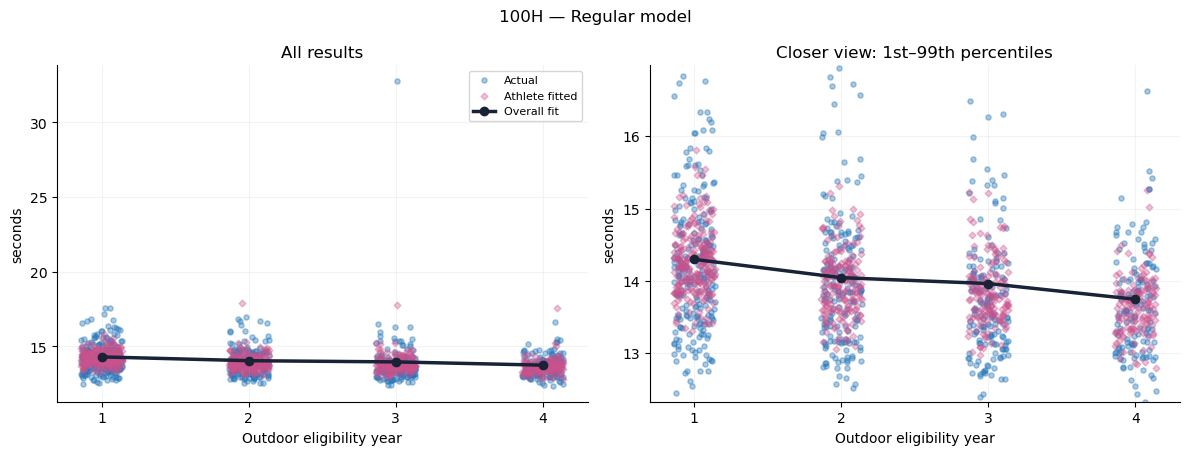

Blue = actual; pink = athlete fitted; dark = overall fit. Hover shows athlete details. Log-chart dots use the fitted log target; tooltip means include back-transformation correction. 100H — Regular: hover over a point 11.091 15.679 20.266 24.854 29.441 34.029 1 2 3 4 Outdoor eligibility year; lower is faster Actual result
Sophusson Smith, Naivasha
Washington
Season: 2016; eligibility: 3
Actual: 13.810 seconds
Fitted mean: 13.909 seconds
Athlete ID: athlete_3749586 Fitted result on model scale
Sophusson Smith, Naivasha
Washington
Season: 2016; eligibility: 3
Actual: 13.810 seconds
Fitted mean: 13.909 seconds
Athlete ID: athlete_3749586 Actual result
Johonnot, Karli
Duke
Season: 2016; eligibility: 4
Actual: 14.300 seconds
Fitted mean: 13.941 seconds
Athlete ID: athlete_3753694 Fitted result on model scale
Johonnot, Karli
Duke
Season: 2016; eligibility: 4
Actual: 14.300 seconds
Fitted mean: 13.941 seconds
Athlete ID: athlete_3753694 Actual result
Maslowski, Teddi
Duke
Season: 2016; eligibility: 4
Actual: 13.430 seconds
Fitted mean: 13.634 seconds
Athlete ID: athlete_3753698 Fitted result on model scale
Maslowski, Teddi
Duke
Season: 2016; eligibility: 4
Actual: 13.430 seconds
Fitted mean: 13.634 seconds
Athlete ID: athlete_3753698 Actual result
Merkley, Erin
BYU
Season: 2016; eligibility: 4
Actual: 14.750 seconds
Fitted mean: 14.100 seconds
Athlete ID: athlete_3755585 Fitted result on model scale
Merkley, Erin
BYU
Season: 2016; eligibility: 4
Actual: 14.750 seconds
Fitted mean: 14.100 seconds
Athlete ID: athlete_3755585 Actual result
Davis, Chalese
South Carolina
Season: 2016; eligibility: 4
Actual: 13.560 seconds
Fitted mean: 13.680 seconds
Athlete ID: athlete_3756352 Fitted result on model scale
Davis, Chalese
South Carolina
Season: 2016; eligibility: 4
Actual: 13.560 seconds
Fitted mean: 13.680 seconds
Athlete ID: athlete_3756352 Actual result
Graham, Sarah
South Carolina
Season: 2016; eligibility: 4
Actual: 13.930 seconds
Fitted mean: 13.811 seconds
Athlete ID: athlete_3756353 Fitted result on model scale
Graham, Sarah
South Carolina
Season: 2016; eligibility: 4
Actual: 13.930 seconds
Fitted mean: 13.811 seconds
Athlete ID: athlete_3756353 Actual result
Smith, C.J.
Washington
Season: 2016; eligibility: 4
Actual: 14.810 seconds
Fitted mean: 14.121 seconds
Athlete ID: athlete_4063531 Fitted result on model scale
Smith, C.J.
Washington
Season: 2016; eligibility: 4
Actual: 14.810 seconds
Fitted mean: 14.121 seconds
Athlete ID: athlete_4063531 Actual result
Gamble, Passion
Alabama
Season: 2017; eligibility: 4
Actual: 14.250 seconds
Fitted mean: 13.923 seconds
Athlete ID: athlete_4167051 Fitted result on model scale
Gamble, Passion
Alabama
Season: 2017; eligibility: 4
Actual: 14.250 seconds
Fitted mean: 13.923 seconds
Athlete ID: athlete_4167051 Actual result
Storm, Kaci
Iowa State
Season: 2016; eligibility: 3
Actual: 14.200 seconds
Fitted mean: 14.047 seconds
Athlete ID: athlete_4172512 Fitted result on model scale
Storm, Kaci
Iowa State
Season: 2016; eligibility: 3
Actual: 14.200 seconds
Fitted mean: 14.047 seconds
Athlete ID: athlete_4172512 Actual result
Saunders, Sha'Keela
Kentucky
Season: 2016; eligibility: 3
Actual: 13.990 seconds
Fitted mean: 13.972 seconds
Athlete ID: athlete_4177198 Fitted result on model scale
Saunders, Sha'Keela
Kentucky
Season: 2016; eligibility: 3
Actual: 13.990 seconds
Fitted mean: 13.972 seconds
Athlete ID: athlete_4177198 Actual result
Hicks, Traci
Arizona
Season: 2016; eligibility: 4
Actual: 13.570 seconds
Fitted mean: 13.684 seconds
Athlete ID: athlete_4190677 Fitted result on model scale
Hicks, Traci
Arizona
Season: 2016; eligibility: 4
Actual: 13.570 seconds
Fitted mean: 13.684 seconds
Athlete ID: athlete_4190677 Actual result
Stueckle, Kimberly
Washington
Season: 2016; eligibility: 4
Actual: 14.000 seconds
Fitted mean: 13.835 seconds
Athlete ID: athlete_4201950 Fitted result on model scale
Stueckle, Kimberly
Washington
Season: 2016; eligibility: 4
Actual: 14.000 seconds
Fitted mean: 13.835 seco

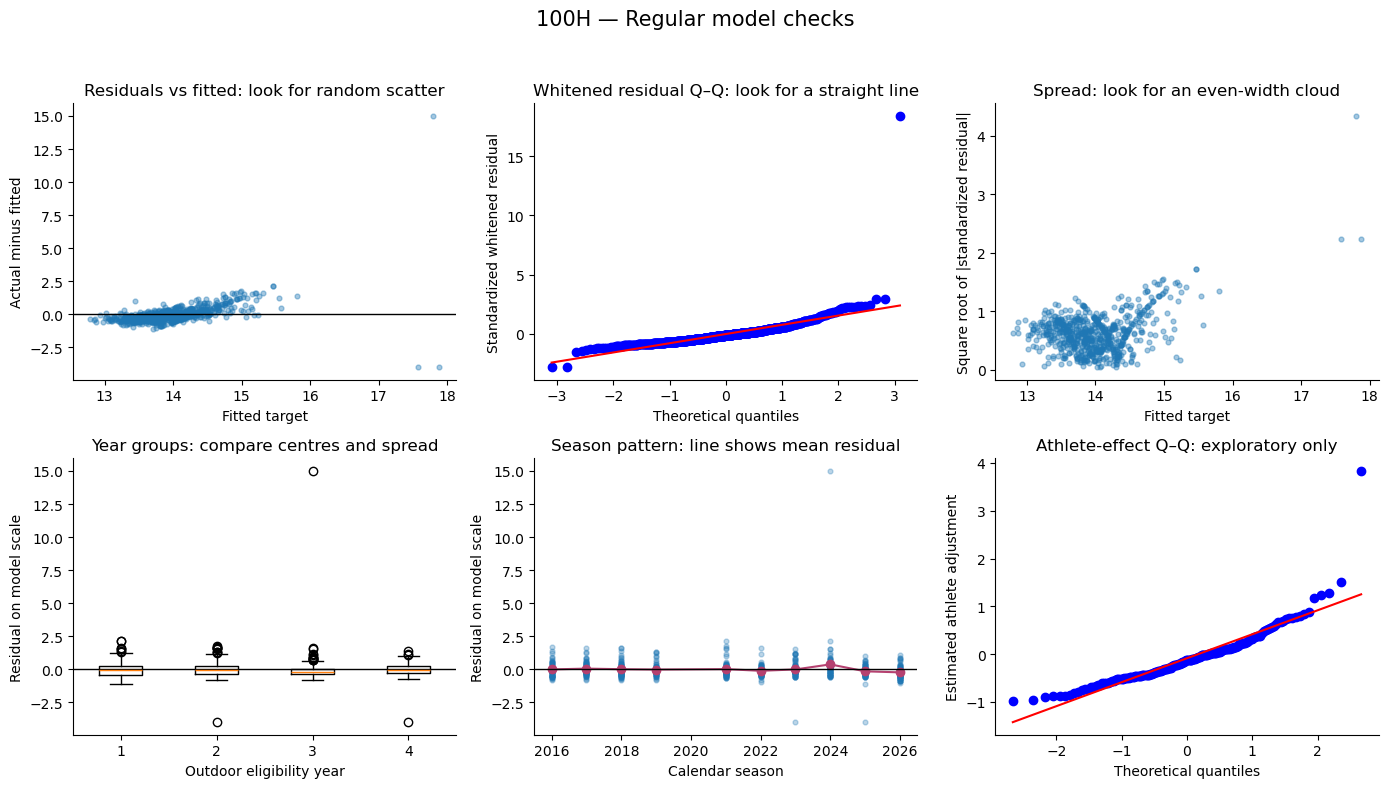

,Diagnostic,Value
0,QQ correlation,0.773461
1,Whitened residual skew,9.10012
2,Whitened excess kurtosis,159.810986
3,Largest absolute standardized conditional resi...,18.82639
4,Conditional residual SD: largest year / smalle...,2.496403
5,Adjacent observed-season residual correlation,-0.336239
6,Within-athlete residual pairs,314
7,Athlete variance,0.438937
8,Residual variance,0.806437
9,Converged,True


Five largest standardized conditional residuals (flags for inspection, not deletion rules):


,athlete,school,season,outdoor_eligibility_year,best_performance,residual_target,standardized_conditional_residual,source_url
323,"Middleton, Lindsey",BYU,2024,3,32.80,15.0048,18.8264,https://www.tfrrs.org/results/84592/5242860/20...
322,"Middleton, Lindsey",BYU,2023,2,13.89,-3.9861,-4.9998,https://www.tfrrs.org/results/81215/4928527/BY...
324,"Middleton, Lindsey",BYU,2025,4,13.60,-3.9778,-4.9939,https://www.tfrrs.org/results/90548/5599991/Ag...
596,"Buller, Sophia",Clemson,2024,1,17.60,2.1385,2.9654,https://www.tfrrs.org/results/84671/5119626/Ch...
460,"Tolbert, Kayla",Alabama,2021,1,17.60,2.1385,2.9654,https://www.tfrrs.org/results/68395/4166890/Pe...


Sensitivity refits; the main model keeps all included rows:


,Check,Athlete,Rows retained,Fourth-year coefficient,Fourth-year percent change,Largest fixed-coefficient change / original SE,Converged
0,Omit one screened athlete,"Middleton, Lindsey",702,-0.43900,NaN,1.02495,True
1,Omit one screened athlete,"Tolbert, Kayla",704,-0.54048,NaN,0.19432,True
2,Omit one screened athlete,"Buller, Sophia",704,-0.54048,NaN,0.19432,True
3,Omit one screened athlete,"Brewer, Anna",704,-0.55194,NaN,0.12045,True
4,Omit one screened athlete,"Carden, Kelley",704,-0.55193,NaN,0.11908,True
5,Subset: selected best has known wind <= +2,Not a best-legal-mark reselection,557,-0.62793,NaN,1.38045,True



100H — Log regression
log(best performance) = 2.65844 -0.01673×Year2 -0.02426×Year3 -0.03672×Year4 + athlete adjustment + error


,Comparison,Coefficient,Approx. SE,Approx. lower 95%,Approx. upper 95%,p_value,percent_difference,percent_lower_95,percent_upper_95
0,First-year intercept,2.65844,0.00424,2.65014,2.66675,0.00000,NaN,NaN,NaN
1,Year 2 vs 1,-0.01673,0.00511,-0.02674,-0.00671,0.00106,-1.65864,-2.63828,-0.66914
2,Year 3 vs 1,-0.02426,0.00552,-0.03507,-0.01345,0.00001,-2.39679,-3.44619,-1.33598
3,Year 4 vs 1,-0.03672,0.00600,-0.04848,-0.02495,0.00000,-3.60528,-4.73277,-2.46444


Fourth year vs first: -3.605 percent. Negative means faster.


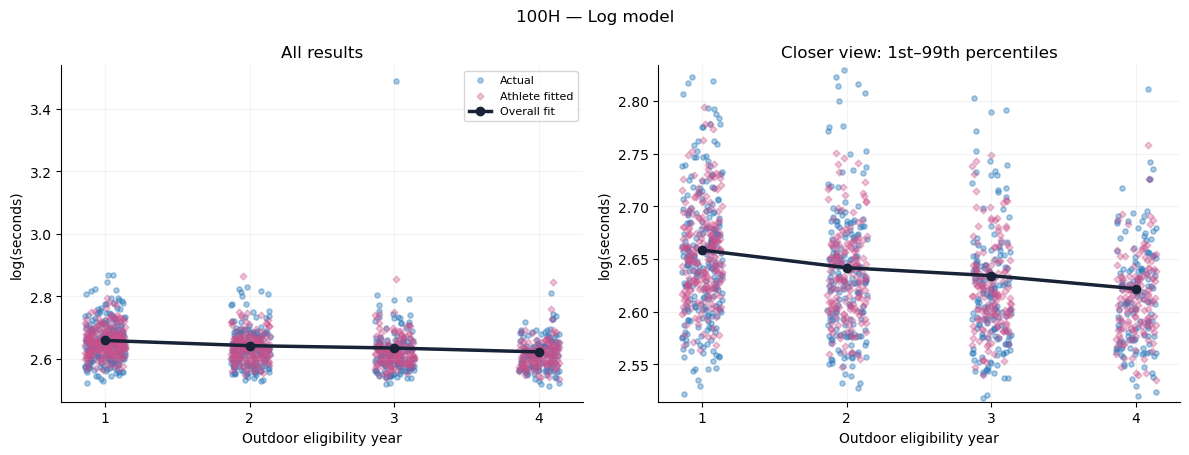

Blue = actual; pink = athlete fitted; dark = overall fit. Hover shows athlete details. Log-chart dots use the fitted log target; tooltip means include back-transformation correction. 100H — Log: hover over a point 2.452 2.672 2.891 3.110 3.330 3.549 1 2 3 4 Outdoor eligibility year; lower is faster Actual result
Sophusson Smith, Naivasha
Washington
Season: 2016; eligibility: 3
Actual: 13.810 seconds
Fitted mean: 13.884 seconds
Athlete ID: athlete_3749586 Fitted result on model scale
Sophusson Smith, Naivasha
Washington
Season: 2016; eligibility: 3
Actual: 13.810 seconds
Fitted mean: 13.884 seconds
Athlete ID: athlete_3749586 Actual result
Johonnot, Karli
Duke
Season: 2016; eligibility: 4
Actual: 14.300 seconds
Fitted mean: 14.088 seconds
Athlete ID: athlete_3753694 Fitted result on model scale
Johonnot, Karli
Duke
Season: 2016; eligibility: 4
Actual: 14.300 seconds
Fitted mean: 14.088 seconds
Athlete ID: athlete_3753694 Actual result
Maslowski, Teddi
Duke
Season: 2016; eligibility: 4
Actual: 13.430 seconds
Fitted mean: 13.592 seconds
Athlete ID: athlete_3753698 Fitted result on model scale
Maslowski, Teddi
Duke
Season: 2016; eligibility: 4
Actual: 13.430 seconds
Fitted mean: 13.592 seconds
Athlete ID: athlete_3753698 Actual result
Merkley, Erin
BYU
Season: 2016; eligibility: 4
Actual: 14.750 seconds
Fitted mean: 14.339 seconds
Athlete ID: athlete_3755585 Fitted result on model scale
Merkley, Erin
BYU
Season: 2016; eligibility: 4
Actual: 14.750 seconds
Fitted mean: 14.339 seconds
Athlete ID: athlete_3755585 Actual result
Davis, Chalese
South Carolina
Season: 2016; eligibility: 4
Actual: 13.560 seconds
Fitted mean: 13.667 seconds
Athlete ID: athlete_3756352 Fitted result on model scale
Davis, Chalese
South Carolina
Season: 2016; eligibility: 4
Actual: 13.560 seconds
Fitted mean: 13.667 seconds
Athlete ID: athlete_3756352 Actual result
Graham, Sarah
South Carolina
Season: 2016; eligibility: 4
Actual: 13.930 seconds
Fitted mean: 13.879 seconds
Athlete ID: athlete_3756353 Fitted result on model scale
Graham, Sarah
South Carolina
Season: 2016; eligibility: 4
Actual: 13.930 seconds
Fitted mean: 13.879 seconds
Athlete ID: athlete_3756353 Actual result
Smith, C.J.
Washington
Season: 2016; eligibility: 4
Actual: 14.810 seconds
Fitted mean: 14.373 seconds
Athlete ID: athlete_4063531 Fitted result on model scale
Smith, C.J.
Washington
Season: 2016; eligibility: 4
Actual: 14.810 seconds
Fitted mean: 14.373 seconds
Athlete ID: athlete_4063531 Actual result
Gamble, Passion
Alabama
Season: 2017; eligibility: 4
Actual: 14.250 seconds
Fitted mean: 14.060 seconds
Athlete ID: athlete_4167051 Fitted result on model scale
Gamble, Passion
Alabama
Season: 2017; eligibility: 4
Actual: 14.250 seconds
Fitted mean: 14.060 seconds
Athlete ID: athlete_4167051 Actual result
Storm, Kaci
Iowa State
Season: 2016; eligibility: 3
Actual: 14.200 seconds
Fitted mean: 14.107 seconds
Athlete ID: athlete_4172512 Fitted result on model scale
Storm, Kaci
Iowa State
Season: 2016; eligibility: 3
Actual: 14.200 seconds
Fitted mean: 14.107 seconds
Athlete ID: athlete_4172512 Actual result
Saunders, Sha'Keela
Kentucky
Season: 2016; eligibility: 3
Actual: 13.990 seconds
Fitted mean: 13.987 seconds
Athlete ID: athlete_4177198 Fitted result on model scale
Saunders, Sha'Keela
Kentucky
Season: 2016; eligibility: 3
Actual: 13.990 seconds
Fitted mean: 13.987 seconds
Athlete ID: athlete_4177198 Actual result
Hicks, Traci
Arizona
Season: 2016; eligibility: 4
Actual: 13.570 seconds
Fitted mean: 13.673 seconds
Athlete ID: athlete_4190677 Fitted result on model scale
Hicks, Traci
Arizona
Season: 2016; eligibility: 4
Actual: 13.570 seconds
Fitted mean: 13.673 seconds
Athlete ID: athlete_4190677 Actual result
Stueckle, Kimberly
Washington
Season: 2016; eligibility: 4
Actual: 14.000 seconds
Fitted mean: 13.918 seconds
Athlete ID: athlete_4201950 Fitted result on model scale
Stueckle, Kimberly
Washington
Season: 2016; eligibility: 4
Actual: 14.000 seconds
Fitted mean: 13.918 seconds
Athlet

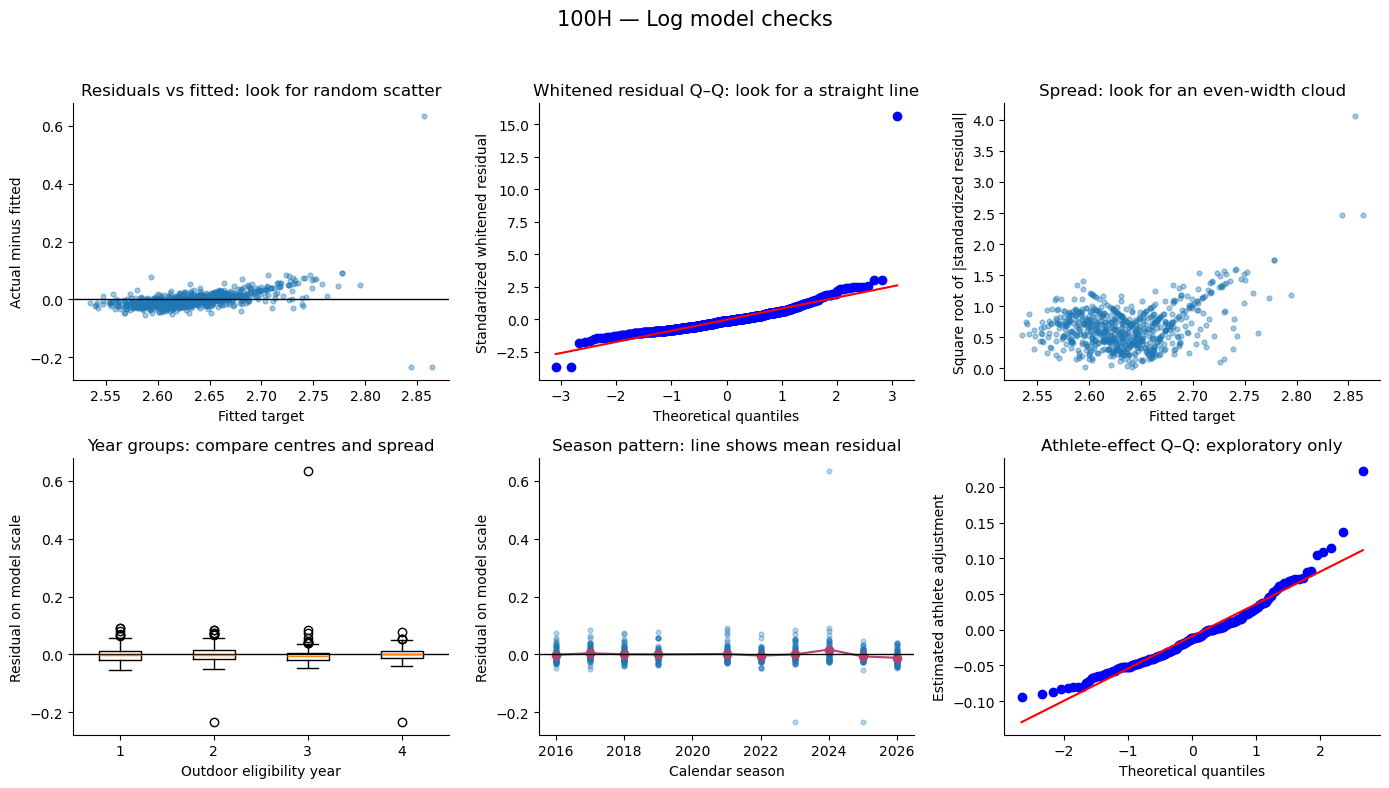

,Diagnostic,Value
0,QQ correlation,0.848441
1,Whitened residual skew,5.747198
2,Whitened excess kurtosis,84.22475
3,Largest absolute standardized conditional resi...,16.500082
4,Conditional residual SD: largest year / smalle...,2.079655
5,Adjacent observed-season residual correlation,-0.491224
6,Within-athlete residual pairs,314
7,Athlete variance,0.002698
8,Residual variance,0.002028
9,Converged,True


Five largest standardized conditional residuals (flags for inspection, not deletion rules):


,athlete,school,season,outdoor_eligibility_year,best_performance,residual_target,standardized_conditional_residual,source_url
323,"Middleton, Lindsey",BYU,2024,3,32.80,0.6339,16.5001,https://www.tfrrs.org/results/84592/5242860/20...
324,"Middleton, Lindsey",BYU,2025,4,13.60,-0.2340,-6.0942,https://www.tfrrs.org/results/90548/5599991/Ag...
322,"Middleton, Lindsey",BYU,2023,2,13.89,-0.2329,-6.0600,https://www.tfrrs.org/results/81215/4928527/BY...
596,"Buller, Sophia",Clemson,2024,1,17.60,0.0899,3.0527,https://www.tfrrs.org/results/84671/5119626/Ch...
460,"Tolbert, Kayla",Alabama,2021,1,17.60,0.0899,3.0527,https://www.tfrrs.org/results/68395/4166890/Pe...


Sensitivity refits; the main model keeps all included rows:


,Check,Athlete,Rows retained,Fourth-year coefficient,Fourth-year percent change,Largest fixed-coefficient change / original SE,Converged
0,Omit one screened athlete,"Middleton, Lindsey",702,-0.03136,-3.08703,0.89323,True
1,Omit one screened athlete,"Tolbert, Kayla",704,-0.03617,-3.55231,0.19203,True
2,Omit one screened athlete,"Buller, Sophia",704,-0.03617,-3.55231,0.19203,True
3,Omit one screened athlete,"Brewer, Anna",704,-0.03672,-3.60579,0.11073,True
4,Omit one screened athlete,"Carden, Kelley",704,-0.03672,-3.60576,0.10955,True
5,Subset: selected best has known wind <= +2,Not a best-legal-mark reselection,557,-0.04117,-4.03336,1.34637,True



Later-season prediction errors in seconds (same returning-athlete rows for all methods):


,Method,Test rows,MAE,RMSE,Bias (predicted minus actual)
0,Regular,314,0.4411,1.2368,0.0666
1,Log,314,0.4292,1.2231,0.0676
2,Previous season,314,0.4332,1.5813,0.1455


,test_season,latest_training_season,training_rows,all_test_rows,returning_test_rows
0,2017,2016,73,76,39
1,2018,2017,149,77,44
2,2019,2018,226,71,45
3,2021,2019,297,78,27
4,2022,2021,375,65,39
5,2023,2022,440,69,36
6,2024,2023,509,64,31
7,2025,2024,573,61,26
8,2026,2025,634,71,27


Regular MAE minus log MAE = +0.0118 seconds. Positive favours log.
Athlete-cluster bootstrap 95% interval: [+0.0039, +0.0204] seconds. This resamples held-out errors without refitting models; it is descriptive uncertainty, not a definitive model-selection test.


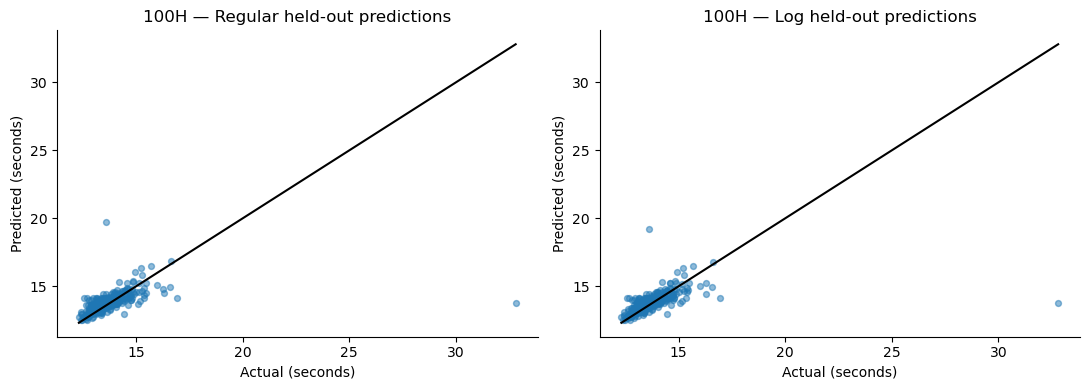

In [7]:
ALL_RESULTS['100H'] = evaluate_event('100H', DATA['100H'])

## 400H: my models and checks

I use each athlete’s **fastest recorded time per season**. Lower times are better.

Each model has its own equation, results, charts, and error checks. I also check whether unusual results affect my findings and how well the models predict later seasons.

**Year2, Year3, and Year4** tell my models the athlete’s eligibility year. The matching year gets a 1; the others get a 0. For first year, all three are 0.

The **athlete adjustment** accounts for each person’s usual speed. The **error** is the part my model does not explain.

501 athlete-season bests; 272 athlete IDs; 137 athletes with repeated seasons.


,count,mean,std,min,max
outdoor_eligibility_year,,,,,
1,155,61.524,3.342,52.75,75.38
2,120,60.523,2.939,54.48,67.12
3,123,59.846,3.532,53.15,76.23
4,103,58.986,2.736,54.52,67.05



400H — Regular regression
best performance = 61.41983 -0.92946×Year2 -1.32704×Year3 -1.80495×Year4 + athlete adjustment + error


,Comparison,Coefficient,Approx. SE,Approx. lower 95%,Approx. upper 95%,p_value
0,First-year intercept,61.41983,0.23481,60.95961,61.88006,0.00000
1,Year 2 vs 1,-0.92946,0.23487,-1.38980,-0.46911,0.00008
2,Year 3 vs 1,-1.32704,0.24812,-1.81337,-0.84072,0.00000
3,Year 4 vs 1,-1.80495,0.28016,-2.35406,-1.25585,0.00000


Fourth year vs first: -1.805 seconds. Negative means faster.


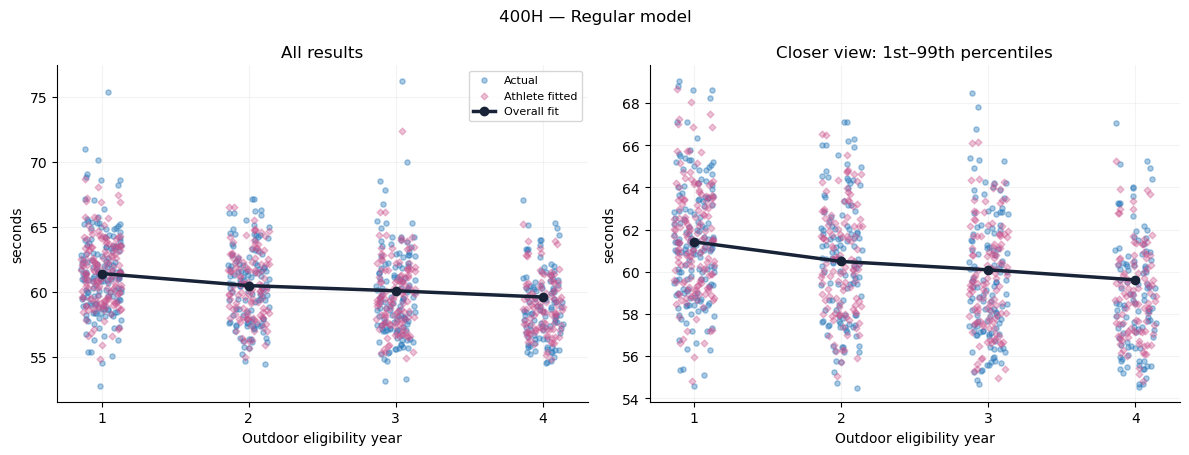

Blue = actual; pink = athlete fitted; dark = overall fit. Hover shows athlete details. Log-chart dots use the fitted log target; tooltip means include back-transformation correction. 400H — Regular: hover over a point 51.341 56.601 61.860 67.120 72.379 77.639 1 2 3 4 Outdoor eligibility year; lower is faster Actual result
Maslowski, Teddi
Duke
Season: 2016; eligibility: 4
Actual: 59.440 seconds
Fitted mean: 59.482 seconds
Athlete ID: athlete_3753698 Fitted result on model scale
Maslowski, Teddi
Duke
Season: 2016; eligibility: 4
Actual: 59.440 seconds
Fitted mean: 59.482 seconds
Athlete ID: athlete_3753698 Actual result
Packham, Kaylee
BYU
Season: 2016; eligibility: 4
Actual: 58.650 seconds
Fitted mean: 58.883 seconds
Athlete ID: athlete_4213515 Fitted result on model scale
Packham, Kaylee
BYU
Season: 2016; eligibility: 4
Actual: 58.650 seconds
Fitted mean: 58.883 seconds
Athlete ID: athlete_4213515 Actual result
Iuel, Amalie
USC
Season: 2016; eligibility: 3
Actual: 56.370 seconds
Fitted mean: 56.659 seconds
Athlete ID: athlete_4642505 Fitted result on model scale
Iuel, Amalie
USC
Season: 2016; eligibility: 3
Actual: 56.370 seconds
Fitted mean: 56.659 seconds
Athlete ID: athlete_4642505 Actual result
Iuel, Amalie
USC
Season: 2017; eligibility: 4
Actual: 55.380 seconds
Fitted mean: 56.181 seconds
Athlete ID: athlete_4642505 Fitted result on model scale
Iuel, Amalie
USC
Season: 2017; eligibility: 4
Actual: 55.380 seconds
Fitted mean: 56.181 seconds
Athlete ID: athlete_4642505 Actual result
Smith, Heather
Virginia
Season: 2016; eligibility: 3
Actual: 58.170 seconds
Fitted mean: 59.088 seconds
Athlete ID: athlete_4658516 Fitted result on model scale
Smith, Heather
Virginia
Season: 2016; eligibility: 3
Actual: 58.170 seconds
Fitted mean: 59.088 seconds
Athlete ID: athlete_4658516 Actual result
Smith, Heather
Virginia
Season: 2017; eligibility: 4
Actual: 59.210 seconds
Fitted mean: 58.610 seconds
Athlete ID: athlete_4658516 Fitted result on model scale
Smith, Heather
Virginia
Season: 2017; eligibility: 4
Actual: 59.210 seconds
Fitted mean: 58.610 seconds
Athlete ID: athlete_4658516 Actual result
Hailey, Nnenya
Arizona
Season: 2016; eligibility: 4
Actual: 54.980 seconds
Fitted mean: 56.097 seconds
Athlete ID: athlete_4670017 Fitted result on model scale
Hailey, Nnenya
Arizona
Season: 2016; eligibility: 4
Actual: 54.980 seconds
Fitted mean: 56.097 seconds
Athlete ID: athlete_4670017 Actual result
Monteverde-Dalton, Alyssa
BYU
Season: 2016; eligibility: 3
Actual: 62.000 seconds
Fitted mean: 61.134 seconds
Athlete ID: athlete_4674800 Fitted result on model scale
Monteverde-Dalton, Alyssa
BYU
Season: 2016; eligibility: 3
Actual: 62.000 seconds
Fitted mean: 61.134 seconds
Athlete ID: athlete_4674800 Actual result
Monteverde-Dalton, Alyssa
BYU
Season: 2018; eligibility: 4
Actual: 60.120 seconds
Fitted mean: 60.656 seconds
Athlete ID: athlete_4674800 Fitted result on model scale
Monteverde-Dalton, Alyssa
BYU
Season: 2018; eligibility: 4
Actual: 60.120 seconds
Fitted mean: 60.656 seconds
Athlete ID: athlete_4674800 Actual result
Porter, Brenna
BYU
Season: 2017; eligibility: 2
Actual: 57.650 seconds
Fitted mean: 57.935 seconds
Athlete ID: athlete_4674802 Fitted result on model scale
Porter, Brenna
BYU
Season: 2017; eligibility: 2
Actual: 57.650 seconds
Fitted mean: 57.935 seconds
Athlete ID: athlete_4674802 Actual result
Porter, Brenna
BYU
Season: 2018; eligibility: 3
Actual: 57.180 seconds
Fitted mean: 57.537 seconds
Athlete ID: athlete_4674802 Fitted result on model scale
Porter, Brenna
BYU
Season: 2018; eligibility: 3
Actual: 57.180 seconds
Fitted mean: 57.537 seconds
Athlete ID: athlete_4674802 Actual result
Porter, Brenna
BYU
Season: 2019; eligibility: 4
Actual: 56.890 seconds
Fitted mean: 57.059 seconds
Athlete ID: athlete_4674802 Fitted result on model scale
Porter, Brenna
BYU
Season: 2019; eligibility: 4
Actual: 56.890 seconds
Fitted mean: 57.059 seconds
Athlete ID: athlete_4674802 Actual result
Lewis, Amber
Stanford
Season: 2016; elig

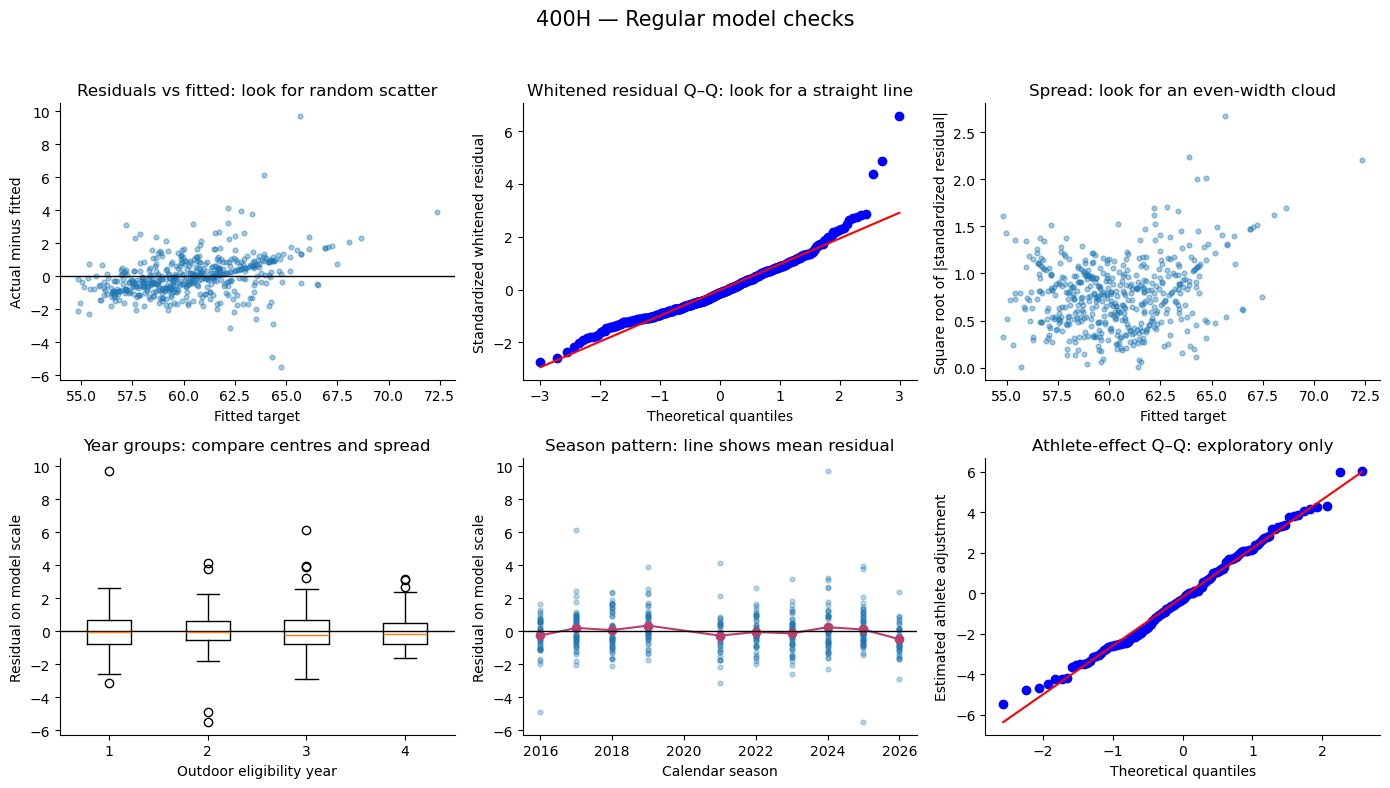

,Diagnostic,Value
0,QQ correlation,0.967356
1,Whitened residual skew,1.216685
2,Whitened excess kurtosis,4.81226
3,Largest absolute standardized conditional resi...,7.13309
4,Conditional residual SD: largest year / smalle...,1.324166
5,Adjacent observed-season residual correlation,-0.43851
6,Within-athlete residual pairs,229
7,Athlete variance,8.433913
8,Residual variance,2.67745
9,Converged,True


Five largest standardized conditional residuals (flags for inspection, not deletion rules):


,athlete,school,season,outdoor_eligibility_year,best_performance,residual_target,standardized_conditional_residual,source_url
410,"Nebel, Isabelle",Clemson,2024,1,75.38,9.7048,7.1331,https://www.tfrrs.org/results/81397/5112723/UC...
24,"Dowell, Kristen",Nebraska,2017,3,70.02,6.1097,4.9778,https://www.tfrrs.org/results/51117/3120350/To...
77,"Woodley, Alexis",Virginia,2019,3,76.23,3.8885,4.8549,https://www.tfrrs.org/results/57295/3679160/Wi...
411,"Nebel, Isabelle",Clemson,2025,2,59.25,-5.4957,-4.0392,https://www.tfrrs.org/results/91057/5657842/AC...
23,"Dowell, Kristen",Nebraska,2016,2,59.41,-4.8978,-3.9903,https://www.tfrrs.org/results/46104/2827397/Ka...


Sensitivity refits; the main model keeps all included rows:


,Check,Athlete,Rows retained,Fourth-year coefficient,Fourth-year percent change,Largest fixed-coefficient change / original SE,Converged
0,Omit one screened athlete,"Nebel, Isabelle",498,-1.61253,NaN,0.74373,True
1,Omit one screened athlete,"Dowell, Kristen",499,-1.78818,NaN,0.24398,True
2,Omit one screened athlete,"Woodley, Alexis",500,-1.83657,NaN,0.26844,True
3,Omit one screened athlete,"Akpan, Sophia",498,-1.82538,NaN,0.26293,True
4,Omit one screened athlete,"Moore, Karlie",497,-1.76342,NaN,0.14960,True
5,Subset: previously reviewed eligibility,Different athlete mix; not a full eligibility ...,187,-1.99842,NaN,2.11321,True



400H — Log regression
log(best performance) = 4.11610 -0.01502×Year2 -0.02194×Year3 -0.02965×Year4 + athlete adjustment + error


,Comparison,Coefficient,Approx. SE,Approx. lower 95%,Approx. upper 95%,p_value,percent_difference,percent_lower_95,percent_upper_95
0,First-year intercept,4.11610,0.00381,4.10864,4.12357,0.00000,NaN,NaN,NaN
1,Year 2 vs 1,-0.01502,0.00376,-0.02238,-0.00765,0.00006,-1.49056,-2.21352,-0.76226
2,Year 3 vs 1,-0.02194,0.00397,-0.02973,-0.01415,0.00000,-2.17024,-2.92914,-1.40541
3,Year 4 vs 1,-0.02965,0.00449,-0.03846,-0.02085,0.00000,-2.92175,-3.77266,-2.06332


Fourth year vs first: -2.922 percent. Negative means faster.


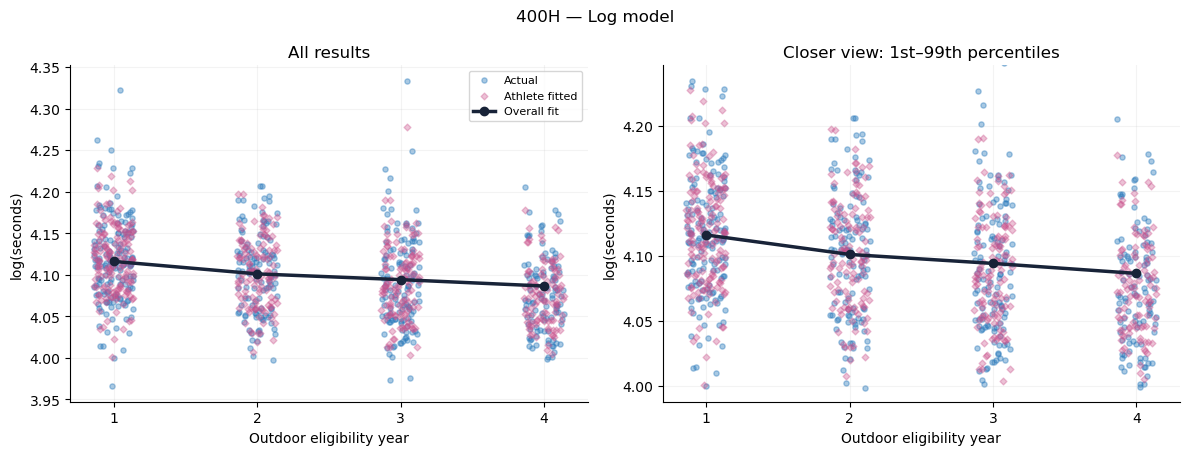

Blue = actual; pink = athlete fitted; dark = overall fit. Hover shows athlete details. Log-chart dots use the fitted log target; tooltip means include back-transformation correction. 400H — Log: hover over a point 3.943 4.026 4.108 4.191 4.273 4.356 1 2 3 4 Outdoor eligibility year; lower is faster Actual result
Maslowski, Teddi
Duke
Season: 2016; eligibility: 4
Actual: 59.440 seconds
Fitted mean: 59.496 seconds
Athlete ID: athlete_3753698 Fitted result on model scale
Maslowski, Teddi
Duke
Season: 2016; eligibility: 4
Actual: 59.440 seconds
Fitted mean: 59.496 seconds
Athlete ID: athlete_3753698 Actual result
Packham, Kaylee
BYU
Season: 2016; eligibility: 4
Actual: 58.650 seconds
Fitted mean: 58.888 seconds
Athlete ID: athlete_4213515 Fitted result on model scale
Packham, Kaylee
BYU
Season: 2016; eligibility: 4
Actual: 58.650 seconds
Fitted mean: 58.888 seconds
Athlete ID: athlete_4213515 Actual result
Iuel, Amalie
USC
Season: 2016; eligibility: 3
Actual: 56.370 seconds
Fitted mean: 56.613 seconds
Athlete ID: athlete_4642505 Fitted result on model scale
Iuel, Amalie
USC
Season: 2016; eligibility: 3
Actual: 56.370 seconds
Fitted mean: 56.613 seconds
Athlete ID: athlete_4642505 Actual result
Iuel, Amalie
USC
Season: 2017; eligibility: 4
Actual: 55.380 seconds
Fitted mean: 56.178 seconds
Athlete ID: athlete_4642505 Fitted result on model scale
Iuel, Amalie
USC
Season: 2017; eligibility: 4
Actual: 55.380 seconds
Fitted mean: 56.178 seconds
Athlete ID: athlete_4642505 Actual result
Smith, Heather
Virginia
Season: 2016; eligibility: 3
Actual: 58.170 seconds
Fitted mean: 59.083 seconds
Athlete ID: athlete_4658516 Fitted result on model scale
Smith, Heather
Virginia
Season: 2016; eligibility: 3
Actual: 58.170 seconds
Fitted mean: 59.083 seconds
Athlete ID: athlete_4658516 Actual result
Smith, Heather
Virginia
Season: 2017; eligibility: 4
Actual: 59.210 seconds
Fitted mean: 58.629 seconds
Athlete ID: athlete_4658516 Fitted result on model scale
Smith, Heather
Virginia
Season: 2017; eligibility: 4
Actual: 59.210 seconds
Fitted mean: 58.629 seconds
Athlete ID: athlete_4658516 Actual result
Hailey, Nnenya
Arizona
Season: 2016; eligibility: 4
Actual: 54.980 seconds
Fitted mean: 56.036 seconds
Athlete ID: athlete_4670017 Fitted result on model scale
Hailey, Nnenya
Arizona
Season: 2016; eligibility: 4
Actual: 54.980 seconds
Fitted mean: 56.036 seconds
Athlete ID: athlete_4670017 Actual result
Monteverde-Dalton, Alyssa
BYU
Season: 2016; eligibility: 3
Actual: 62.000 seconds
Fitted mean: 61.147 seconds
Athlete ID: athlete_4674800 Fitted result on model scale
Monteverde-Dalton, Alyssa
BYU
Season: 2016; eligibility: 3
Actual: 62.000 seconds
Fitted mean: 61.147 seconds
Athlete ID: athlete_4674800 Actual result
Monteverde-Dalton, Alyssa
BYU
Season: 2018; eligibility: 4
Actual: 60.120 seconds
Fitted mean: 60.677 seconds
Athlete ID: athlete_4674800 Fitted result on model scale
Monteverde-Dalton, Alyssa
BYU
Season: 2018; eligibility: 4
Actual: 60.120 seconds
Fitted mean: 60.677 seconds
Athlete ID: athlete_4674800 Actual result
Porter, Brenna
BYU
Season: 2017; eligibility: 2
Actual: 57.650 seconds
Fitted mean: 57.924 seconds
Athlete ID: athlete_4674802 Fitted result on model scale
Porter, Brenna
BYU
Season: 2017; eligibility: 2
Actual: 57.650 seconds
Fitted mean: 57.924 seconds
Athlete ID: athlete_4674802 Actual result
Porter, Brenna
BYU
Season: 2018; eligibility: 3
Actual: 57.180 seconds
Fitted mean: 57.524 seconds
Athlete ID: athlete_4674802 Fitted result on model scale
Porter, Brenna
BYU
Season: 2018; eligibility: 3
Actual: 57.180 seconds
Fitted mean: 57.524 seconds
Athlete ID: athlete_4674802 Actual result
Porter, Brenna
BYU
Season: 2019; eligibility: 4
Actual: 56.890 seconds
Fitted mean: 57.082 seconds
Athlete ID: athlete_4674802 Fitted result on model scale
Porter, Brenna
BYU
Season: 2019; eligibility: 4
Actual: 56.890 seconds
Fitted mean: 57.082 seconds
Athlete ID: athlete_4674802 Actual result
Lewis, Amber
Stanford
Season: 2016; eligibility: 2

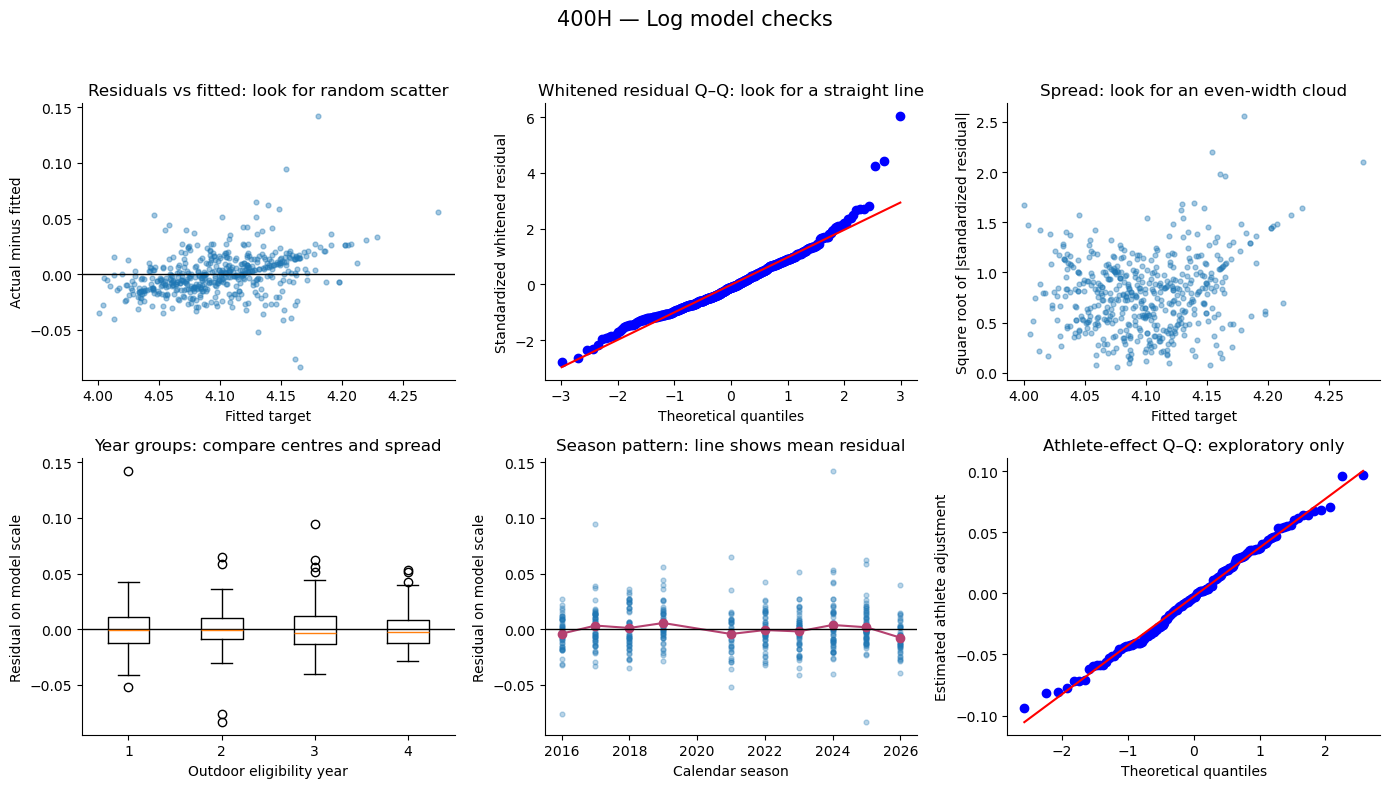

,Diagnostic,Value
0,QQ correlation,0.976834
1,Whitened residual skew,0.950973
2,Whitened excess kurtosis,3.330097
3,Largest absolute standardized conditional resi...,6.556602
4,Conditional residual SD: largest year / smalle...,1.260561
5,Adjacent observed-season residual correlation,-0.438001
6,Within-athlete residual pairs,229
7,Athlete variance,0.002263
8,Residual variance,0.000683
9,Converged,True


Five largest standardized conditional residuals (flags for inspection, not deletion rules):


,athlete,school,season,outdoor_eligibility_year,best_performance,residual_target,standardized_conditional_residual,source_url
410,"Nebel, Isabelle",Clemson,2024,1,75.38,0.1423,6.5566,https://www.tfrrs.org/results/81397/5112723/UC...
24,"Dowell, Kristen",Nebraska,2017,3,70.02,0.0947,4.8431,https://www.tfrrs.org/results/51117/3120350/To...
77,"Woodley, Alexis",Virginia,2019,3,76.23,0.0555,4.4271,https://www.tfrrs.org/results/57295/3679160/Wi...
23,"Dowell, Kristen",Nebraska,2016,2,59.41,-0.0766,-3.9177,https://www.tfrrs.org/results/46104/2827397/Ka...
411,"Nebel, Isabelle",Clemson,2025,2,59.25,-0.0835,-3.8466,https://www.tfrrs.org/results/91057/5657842/AC...


Sensitivity refits; the main model keeps all included rows:


,Check,Athlete,Rows retained,Fourth-year coefficient,Fourth-year percent change,Largest fixed-coefficient change / original SE,Converged
0,Omit one screened athlete,"Nebel, Isabelle",498,-0.02695,-2.65867,0.68078,True
1,Omit one screened athlete,"Dowell, Kristen",499,-0.02942,-2.89866,0.23851,True
2,Omit one screened athlete,"Woodley, Alexis",500,-0.03007,-2.96257,0.23510,True
3,Omit one screened athlete,"Akpan, Sophia",498,-0.02999,-2.95407,0.26022,True
4,Omit one screened athlete,"Moore, Karlie",497,-0.02900,-2.85845,0.14829,True
5,Subset: previously reviewed eligibility,Different athlete mix; not a full eligibility ...,187,-0.03339,-3.28425,1.95625,True



Later-season prediction errors in seconds (same returning-athlete rows for all methods):


,Method,Test rows,MAE,RMSE,Bias (predicted minus actual)
0,Regular,229,1.6624,2.3230,0.0803
1,Log,229,1.6591,2.3116,0.0738
2,Previous season,229,1.4871,2.1631,0.4240


,test_season,latest_training_season,training_rows,all_test_rows,returning_test_rows
0,2017,2016,49,52,24
1,2018,2017,101,52,35
2,2019,2018,153,50,30
3,2021,2019,203,38,15
4,2022,2021,241,46,26
5,2023,2022,287,56,24
6,2024,2023,343,56,27
7,2025,2024,399,58,27
8,2026,2025,457,44,21


Regular MAE minus log MAE = +0.0033 seconds. Positive favours log.
Athlete-cluster bootstrap 95% interval: [-0.0050, +0.0135] seconds. This resamples held-out errors without refitting models; it is descriptive uncertainty, not a definitive model-selection test.


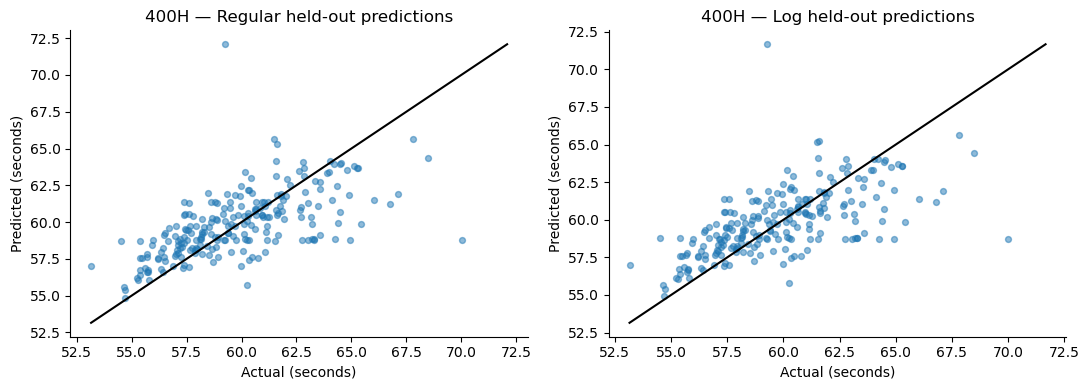

In [9]:
ALL_RESULTS['400H'] = evaluate_event('400H', DATA['400H'])

## 400m: my models and checks

I use each athlete’s **fastest recorded time per season**. Lower times are better.

Each model has its own equation, results, charts, and error checks. I also check whether unusual results affect my findings and how well the models predict later seasons.

**Year2, Year3, and Year4** tell my models the athlete’s eligibility year. The matching year gets a 1; the others get a 0. For first year, all three are 0.

The **athlete adjustment** accounts for each person’s usual speed. The **error** is the part my model does not explain.

984 athlete-season bests; 573 athlete IDs; 256 athletes with repeated seasons.


,count,mean,std,min,max
outdoor_eligibility_year,,,,,
1,280,56.073,3.003,49.80,65.62
2,251,55.413,2.674,49.79,65.60
3,253,54.794,2.589,48.97,63.51
4,200,54.664,2.637,48.79,63.60



400m — Regular regression
best performance = 56.21394 -0.59972×Year2 -0.83197×Year3 -0.83299×Year4 + athlete adjustment + error


,Comparison,Coefficient,Approx. SE,Approx. lower 95%,Approx. upper 95%,p_value
0,First-year intercept,56.21394,0.13963,55.94027,56.48761,0.0
1,Year 2 vs 1,-0.59972,0.12659,-0.84784,-0.35160,0.0
2,Year 3 vs 1,-0.83197,0.13451,-1.09561,-0.56833,0.0
3,Year 4 vs 1,-0.83299,0.15145,-1.12983,-0.53614,0.0


Fourth year vs first: -0.833 seconds. Negative means faster.


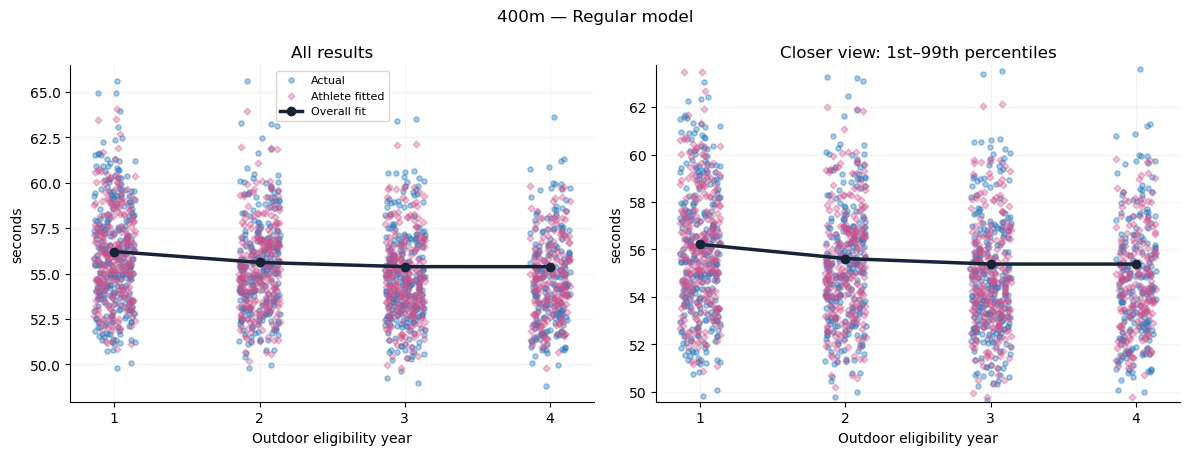

Blue = actual; pink = athlete fitted; dark = overall fit. Hover shows athlete details. Log-chart dots use the fitted log target; tooltip means include back-transformation correction. 400m — Regular: hover over a point 47.780 51.550 55.320 59.090 62.860 66.630 1 2 3 4 Outdoor eligibility year; lower is faster Actual result
Iuel, Amalie
USC
Season: 2017; eligibility: 4
Actual: 51.810 seconds
Fitted mean: 52.409 seconds
Athlete ID: athlete_4642505 Fitted result on model scale
Iuel, Amalie
USC
Season: 2017; eligibility: 4
Actual: 51.810 seconds
Fitted mean: 52.409 seconds
Athlete ID: athlete_4642505 Actual result
Monteverde-Dalton, Alyssa
BYU
Season: 2018; eligibility: 4
Actual: 57.430 seconds
Fitted mean: 57.086 seconds
Athlete ID: athlete_4674800 Fitted result on model scale
Monteverde-Dalton, Alyssa
BYU
Season: 2018; eligibility: 4
Actual: 57.430 seconds
Fitted mean: 57.086 seconds
Athlete ID: athlete_4674800 Actual result
Porter, Brenna
BYU
Season: 2019; eligibility: 4
Actual: 54.500 seconds
Fitted mean: 54.648 seconds
Athlete ID: athlete_4674802 Fitted result on model scale
Porter, Brenna
BYU
Season: 2019; eligibility: 4
Actual: 54.500 seconds
Fitted mean: 54.648 seconds
Athlete ID: athlete_4674802 Actual result
Bonds, Tiana
Arizona
Season: 2017; eligibility: 3
Actual: 59.510 seconds
Fitted mean: 58.818 seconds
Athlete ID: athlete_5126899 Fitted result on model scale
Bonds, Tiana
Arizona
Season: 2017; eligibility: 3
Actual: 59.510 seconds
Fitted mean: 58.818 seconds
Athlete ID: athlete_5126899 Actual result
Thompson, Alyssa
Arizona
Season: 2018; eligibility: 4
Actual: 55.400 seconds
Fitted mean: 55.397 seconds
Athlete ID: athlete_5126921 Fitted result on model scale
Thompson, Alyssa
Arizona
Season: 2018; eligibility: 4
Actual: 55.400 seconds
Fitted mean: 55.397 seconds
Athlete ID: athlete_5126921 Actual result
Whigham, Emma
Iowa State
Season: 2016; eligibility: 1
Actual: 56.570 seconds
Fitted mean: 57.163 seconds
Athlete ID: athlete_5585155 Fitted result on model scale
Whigham, Emma
Iowa State
Season: 2016; eligibility: 1
Actual: 56.570 seconds
Fitted mean: 57.163 seconds
Athlete ID: athlete_5585155 Actual result
Whigham, Emma
Iowa State
Season: 2017; eligibility: 2
Actual: 55.680 seconds
Fitted mean: 56.564 seconds
Athlete ID: athlete_5585155 Fitted result on model scale
Whigham, Emma
Iowa State
Season: 2017; eligibility: 2
Actual: 55.680 seconds
Fitted mean: 56.564 seconds
Athlete ID: athlete_5585155 Actual result
Whigham, Emma
Iowa State
Season: 2018; eligibility: 3
Actual: 56.800 seconds
Fitted mean: 56.331 seconds
Athlete ID: athlete_5585155 Fitted result on model scale
Whigham, Emma
Iowa State
Season: 2018; eligibility: 3
Actual: 56.800 seconds
Fitted mean: 56.331 seconds
Athlete ID: athlete_5585155 Actual result
Whigham, Emma
Iowa State
Season: 2019; eligibility: 4
Actual: 57.530 seconds
Fitted mean: 56.330 seconds
Athlete ID: athlete_5585155 Fitted result on model scale
Whigham, Emma
Iowa State
Season: 2019; eligibility: 4
Actual: 57.530 seconds
Fitted mean: 56.330 seconds
Athlete ID: athlete_5585155 Actual result
Berry, Jasmine
Illinois
Season: 2016; eligibility: 2
Actual: 58.850 seconds
Fitted mean: 58.307 seconds
Athlete ID: athlete_5605110 Fitted result on model scale
Berry, Jasmine
Illinois
Season: 2016; eligibility: 2
Actual: 58.850 seconds
Fitted mean: 58.307 seconds
Athlete ID: athlete_5605110 Actual result
Sutton, April
Arizona
Season: 2017; eligibility: 1
Actual: 57.980 seconds
Fitted mean: 57.642 seconds
Athlete ID: athlete_5612191 Fitted result on model scale
Sutton, April
Arizona
Season: 2017; eligibility: 1
Actual: 57.980 seconds
Fitted mean: 57.642 seconds
Athlete ID: athlete_5612191 Actual result
Sutton, April
Arizona
Season: 2019; eligibility: 3
Actual: 56.760 seconds
Fitted mean: 56.810 seconds
Athlete ID: athlete_5612191 Fitted result on model scale
Sutton, April
Arizona
Season: 2019; eligibility: 3
Actual: 56.760 seconds
Fitted mean: 56.810 seconds
Athlete ID: athlete_5612191 Actual result
Labrie-S

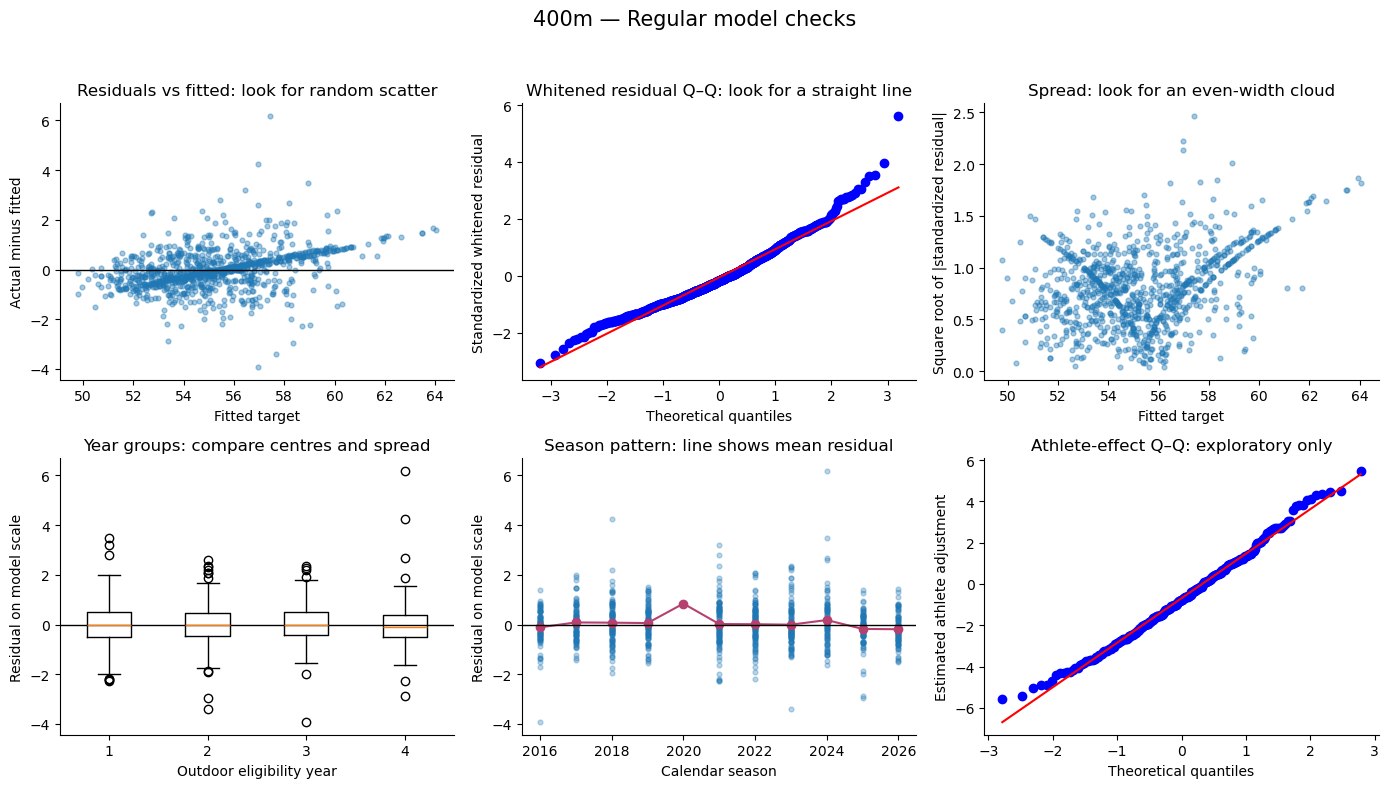

,Diagnostic,Value
0,QQ correlation,0.985292
1,Whitened residual skew,0.72769
2,Whitened excess kurtosis,1.383136
3,Largest absolute standardized conditional resi...,6.083869
4,Conditional residual SD: largest year / smalle...,1.204219
5,Adjacent observed-season residual correlation,-0.501382
6,Within-athlete residual pairs,411
7,Athlete variance,6.790447
8,Residual variance,1.368178
9,Converged,True


Five largest standardized conditional residuals (flags for inspection, not deletion rules):


,athlete,school,season,outdoor_eligibility_year,best_performance,residual_target,standardized_conditional_residual,source_url
803,"Williams, Lily",Baylor,2024,4,63.60,6.1800,6.0839,https://www.tfrrs.org/results/81450/5129001/Cl...
298,"Haith, Briana",South Carolina,2018,4,61.20,4.2442,4.9293,https://www.tfrrs.org/results/54171/3425859/Te...
297,"Haith, Briana",South Carolina,2016,3,53.03,-3.9269,-4.5598,https://www.tfrrs.org/results/43368/2772283/Fl...
673,"Nebel, Isabelle",Clemson,2024,1,62.44,3.4998,4.0613,https://www.tfrrs.org/results/81665/5127770/UC...
50,"Kapoor, Isabelle",Clemson,2024,2,65.60,1.6746,3.5003,https://www.tfrrs.org/results/85539/5220052/US...


Sensitivity refits; the main model keeps all included rows:


,Check,Athlete,Rows retained,Fourth-year coefficient,Fourth-year percent change,Largest fixed-coefficient change / original SE,Converged
0,Omit one screened athlete,"Williams, Lily",980,-0.89461,NaN,0.40691,True
1,Omit one screened athlete,"Haith, Briana",982,-0.85919,NaN,0.22121,True
2,Omit one screened athlete,"Nebel, Isabelle",982,-0.80232,NaN,0.30858,True
3,Omit one screened athlete,"Kapoor, Isabelle",983,-0.83607,NaN,0.09736,True
4,Omit one screened athlete,"Hart, Annalise",981,-0.80486,NaN,0.25106,True



400m — Log regression
log(best performance) = 4.02793 -0.01069×Year2 -0.01506×Year3 -0.01531×Year4 + athlete adjustment + error


,Comparison,Coefficient,Approx. SE,Approx. lower 95%,Approx. upper 95%,p_value,percent_difference,percent_lower_95,percent_upper_95
0,First-year intercept,4.02793,0.00249,4.02305,4.03280,0.0,NaN,NaN,NaN
1,Year 2 vs 1,-0.01069,0.00226,-0.01512,-0.00627,0.0,-1.06371,-1.50078,-0.62470
2,Year 3 vs 1,-0.01506,0.00240,-0.01976,-0.01035,0.0,-1.49454,-1.95681,-1.03009
3,Year 4 vs 1,-0.01531,0.00270,-0.02060,-0.01001,0.0,-1.51921,-2.03935,-0.99630


Fourth year vs first: -1.519 percent. Negative means faster.


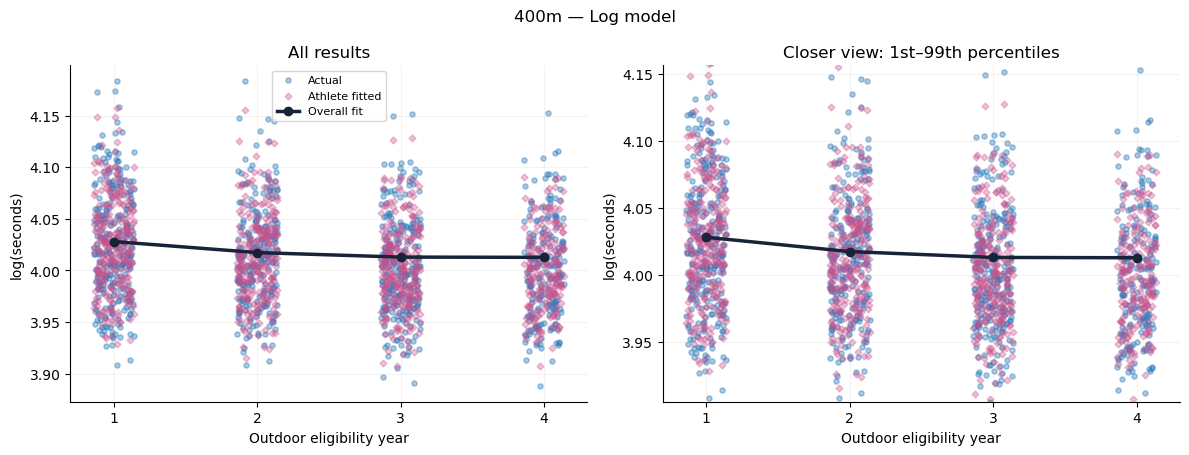

Blue = actual; pink = athlete fitted; dark = overall fit. Hover shows athlete details. Log-chart dots use the fitted log target; tooltip means include back-transformation correction. 400m — Log: hover over a point 3.870 3.936 4.003 4.069 4.135 4.202 1 2 3 4 Outdoor eligibility year; lower is faster Actual result
Iuel, Amalie
USC
Season: 2017; eligibility: 4
Actual: 51.810 seconds
Fitted mean: 52.403 seconds
Athlete ID: athlete_4642505 Fitted result on model scale
Iuel, Amalie
USC
Season: 2017; eligibility: 4
Actual: 51.810 seconds
Fitted mean: 52.403 seconds
Athlete ID: athlete_4642505 Actual result
Monteverde-Dalton, Alyssa
BYU
Season: 2018; eligibility: 4
Actual: 57.430 seconds
Fitted mean: 57.086 seconds
Athlete ID: athlete_4674800 Fitted result on model scale
Monteverde-Dalton, Alyssa
BYU
Season: 2018; eligibility: 4
Actual: 57.430 seconds
Fitted mean: 57.086 seconds
Athlete ID: athlete_4674800 Actual result
Porter, Brenna
BYU
Season: 2019; eligibility: 4
Actual: 54.500 seconds
Fitted mean: 54.655 seconds
Athlete ID: athlete_4674802 Fitted result on model scale
Porter, Brenna
BYU
Season: 2019; eligibility: 4
Actual: 54.500 seconds
Fitted mean: 54.655 seconds
Athlete ID: athlete_4674802 Actual result
Bonds, Tiana
Arizona
Season: 2017; eligibility: 3
Actual: 59.510 seconds
Fitted mean: 58.801 seconds
Athlete ID: athlete_5126899 Fitted result on model scale
Bonds, Tiana
Arizona
Season: 2017; eligibility: 3
Actual: 59.510 seconds
Fitted mean: 58.801 seconds
Athlete ID: athlete_5126899 Actual result
Thompson, Alyssa
Arizona
Season: 2018; eligibility: 4
Actual: 55.400 seconds
Fitted mean: 55.404 seconds
Athlete ID: athlete_5126921 Fitted result on model scale
Thompson, Alyssa
Arizona
Season: 2018; eligibility: 4
Actual: 55.400 seconds
Fitted mean: 55.404 seconds
Athlete ID: athlete_5126921 Actual result
Whigham, Emma
Iowa State
Season: 2016; eligibility: 1
Actual: 56.570 seconds
Fitted mean: 57.188 seconds
Athlete ID: athlete_5585155 Fitted result on model scale
Whigham, Emma
Iowa State
Season: 2016; eligibility: 1
Actual: 56.570 seconds
Fitted mean: 57.188 seconds
Athlete ID: athlete_5585155 Actual result
Whigham, Emma
Iowa State
Season: 2017; eligibility: 2
Actual: 55.680 seconds
Fitted mean: 56.580 seconds
Athlete ID: athlete_5585155 Fitted result on model scale
Whigham, Emma
Iowa State
Season: 2017; eligibility: 2
Actual: 55.680 seconds
Fitted mean: 56.580 seconds
Athlete ID: athlete_5585155 Actual result
Whigham, Emma
Iowa State
Season: 2018; eligibility: 3
Actual: 56.800 seconds
Fitted mean: 56.334 seconds
Athlete ID: athlete_5585155 Fitted result on model scale
Whigham, Emma
Iowa State
Season: 2018; eligibility: 3
Actual: 56.800 seconds
Fitted mean: 56.334 seconds
Athlete ID: athlete_5585155 Actual result
Whigham, Emma
Iowa State
Season: 2019; eligibility: 4
Actual: 57.530 seconds
Fitted mean: 56.319 seconds
Athlete ID: athlete_5585155 Fitted result on model scale
Whigham, Emma
Iowa State
Season: 2019; eligibility: 4
Actual: 57.530 seconds
Fitted mean: 56.319 seconds
Athlete ID: athlete_5585155 Actual result
Berry, Jasmine
Illinois
Season: 2016; eligibility: 2
Actual: 58.850 seconds
Fitted mean: 58.302 seconds
Athlete ID: athlete_5605110 Fitted result on model scale
Berry, Jasmine
Illinois
Season: 2016; eligibility: 2
Actual: 58.850 seconds
Fitted mean: 58.302 seconds
Athlete ID: athlete_5605110 Actual result
Sutton, April
Arizona
Season: 2017; eligibility: 1
Actual: 57.980 seconds
Fitted mean: 57.664 seconds
Athlete ID: athlete_5612191 Fitted result on model scale
Sutton, April
Arizona
Season: 2017; eligibility: 1
Actual: 57.980 seconds
Fitted mean: 57.664 seconds
Athlete ID: athlete_5612191 Actual result
Sutton, April
Arizona
Season: 2019; eligibility: 3
Actual: 56.760 seconds
Fitted mean: 56.802 seconds
Athlete ID: athlete_5612191 Fitted result on model scale
Sutton, April
Arizona
Season: 2019; eligibility: 3
Actual: 56.760 seconds
Fitted mean: 56.802 seconds
Athlete ID: athlete_5612191 Actual result
Labrie-Smith, Hann

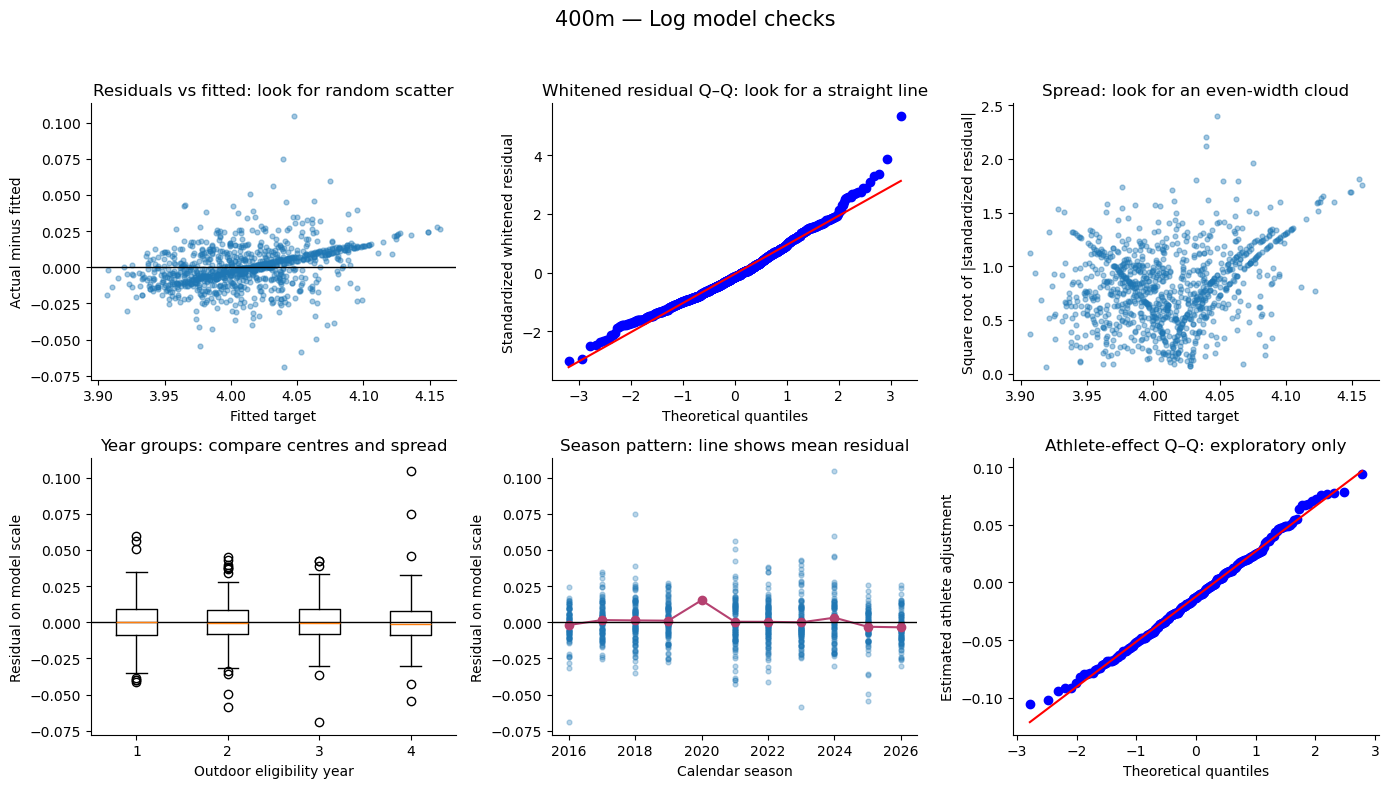

,Diagnostic,Value
0,QQ correlation,0.989837
1,Whitened residual skew,0.583221
2,Whitened excess kurtosis,0.986227
3,Largest absolute standardized conditional resi...,5.766729
4,Conditional residual SD: largest year / smalle...,1.187364
5,Adjacent observed-season residual correlation,-0.489991
6,Within-athlete residual pairs,411
7,Athlete variance,0.002145
8,Residual variance,0.000436
9,Converged,True


Five largest standardized conditional residuals (flags for inspection, not deletion rules):


,athlete,school,season,outdoor_eligibility_year,best_performance,residual_target,standardized_conditional_residual,source_url
803,"Williams, Lily",Baylor,2024,4,63.60,0.1046,5.7667,https://www.tfrrs.org/results/81450/5129001/Cl...
298,"Haith, Briana",South Carolina,2018,4,61.20,0.0745,4.8467,https://www.tfrrs.org/results/54171/3425859/Te...
297,"Haith, Briana",South Carolina,2016,3,53.03,-0.0690,-4.4886,https://www.tfrrs.org/results/43368/2772283/Fl...
673,"Nebel, Isabelle",Clemson,2024,1,62.44,0.0593,3.8556,https://www.tfrrs.org/results/81665/5127770/UC...
50,"Kapoor, Isabelle",Clemson,2024,2,65.60,0.0281,3.2784,https://www.tfrrs.org/results/85539/5220052/US...


Sensitivity refits; the main model keeps all included rows:


,Check,Athlete,Rows retained,Fourth-year coefficient,Fourth-year percent change,Largest fixed-coefficient change / original SE,Converged
0,Omit one screened athlete,"Williams, Lily",980,-0.01637,-1.62349,0.39211,True
1,Omit one screened athlete,"Haith, Briana",982,-0.01578,-1.56565,0.21450,True
2,Omit one screened athlete,"Nebel, Isabelle",982,-0.01480,-1.46940,0.29080,True
3,Omit one screened athlete,"Kapoor, Isabelle",983,-0.01535,-1.52350,0.09184,True
4,Omit one screened athlete,"Hart, Annalise",981,-0.01482,-1.47138,0.24641,True



Later-season prediction errors in seconds (same returning-athlete rows for all methods):


,Method,Test rows,MAE,RMSE,Bias (predicted minus actual)
0,Regular,411,1.1841,1.6187,0.0266
1,Log,411,1.1830,1.6151,0.0339
2,Previous season,411,1.1568,1.5868,0.2230


,test_season,latest_training_season,training_rows,all_test_rows,returning_test_rows
0,2017,2016,89,97,32
1,2018,2017,186,101,50
2,2019,2018,287,96,53
3,2020,2019,383,1,0
4,2021,2020,384,108,34
5,2022,2021,492,113,51
6,2023,2022,605,111,48
7,2024,2023,716,93,58
8,2025,2024,809,86,45
9,2026,2025,895,89,40


Regular MAE minus log MAE = +0.0011 seconds. Positive favours log.
Athlete-cluster bootstrap 95% interval: [-0.0014, +0.0037] seconds. This resamples held-out errors without refitting models; it is descriptive uncertainty, not a definitive model-selection test.


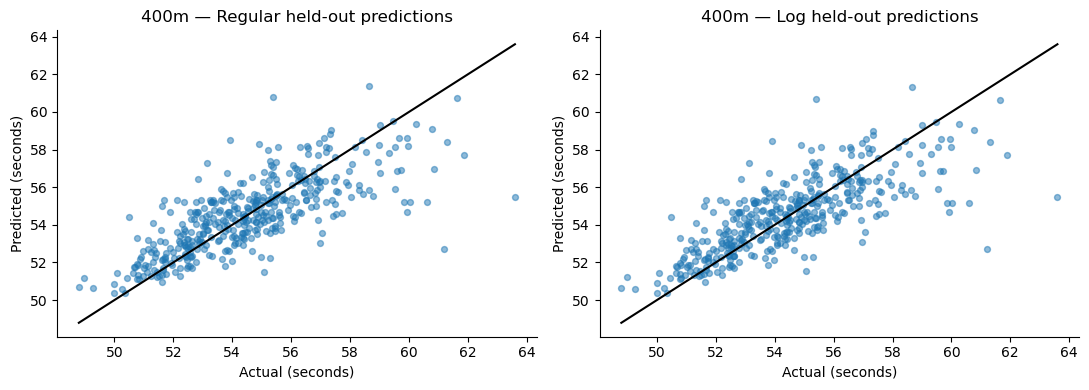

In [11]:
ALL_RESULTS['400m'] = evaluate_event('400m', DATA['400m'])

## Long jump: my models and checks

I use each athlete’s **longest recorded jump per season**. Longer distances are better.

Each model has its own equation, results, charts, and error checks. I also check whether unusual results affect my findings and how well the models predict later seasons.

**Year2, Year3, and Year4** tell my models the athlete’s eligibility year. The matching year gets a 1; the others get a 0. For first year, all three are 0.

The **athlete adjustment** accounts for each person’s usual jump distance. The **error** is the part my model does not explain.

861 athlete-season bests; 460 athlete IDs; 234 athletes with repeated seasons.


,count,mean,std,min,max
outdoor_eligibility_year,,,,,
1,263,5.704,0.491,4.28,6.86
2,218,5.837,0.441,4.61,6.82
3,205,5.945,0.424,4.59,6.88
4,175,6.000,0.451,4.29,7.09



Long Jump — Regular regression
best performance = 5.69619 +0.09731×Year2 +0.16866×Year3 +0.21136×Year4 + athlete adjustment + error


,Comparison,Coefficient,Approx. SE,Approx. lower 95%,Approx. upper 95%,p_value
0,First-year intercept,5.69619,0.02500,5.64719,5.74519,0.00000
1,Year 2 vs 1,0.09731,0.02387,0.05051,0.14410,0.00005
2,Year 3 vs 1,0.16866,0.02592,0.11786,0.21946,0.00000
3,Year 4 vs 1,0.21136,0.02887,0.15478,0.26795,0.00000


Fourth year vs first: +0.211 metres. Positive means farther.


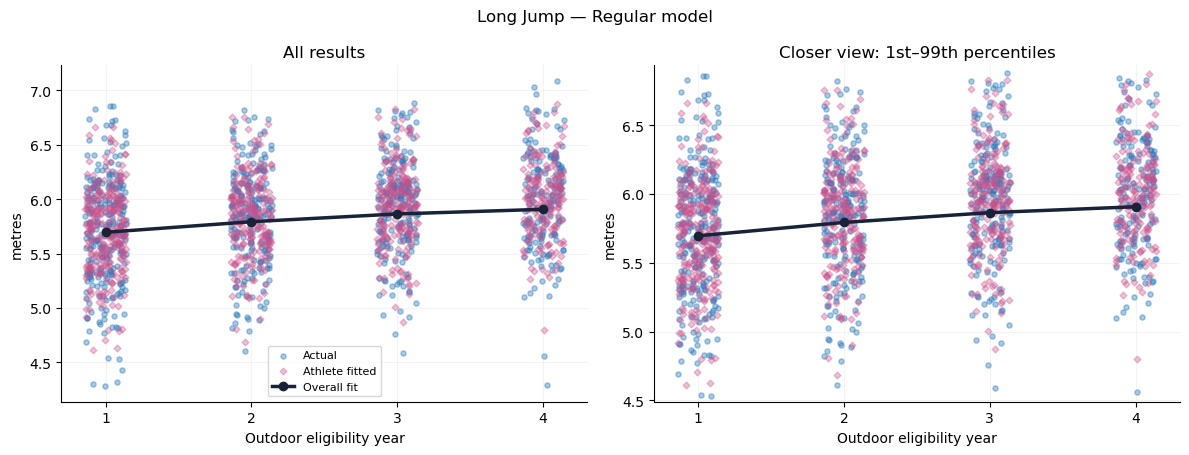

Blue = actual; pink = athlete fitted; dark = overall fit. Hover shows athlete details. Log-chart dots use the fitted log target; tooltip means include back-transformation correction. Long Jump — Regular: hover over a point 4.111 4.741 5.370 6.000 6.629 7.259 1 2 3 4 Outdoor eligibility year; higher is better Actual result
Johonnot, Karli
Duke
Season: 2016; eligibility: 4
Actual: 5.680 metres
Fitted mean: 5.731 metres
Athlete ID: athlete_3753694 Fitted result on model scale
Johonnot, Karli
Duke
Season: 2016; eligibility: 4
Actual: 5.680 metres
Fitted mean: 5.731 metres
Athlete ID: athlete_3753694 Actual result
Maslowski, Teddi
Duke
Season: 2016; eligibility: 4
Actual: 5.810 metres
Fitted mean: 5.832 metres
Athlete ID: athlete_3753698 Fitted result on model scale
Maslowski, Teddi
Duke
Season: 2016; eligibility: 4
Actual: 5.810 metres
Fitted mean: 5.832 metres
Athlete ID: athlete_3753698 Actual result
Merkley, Erin
BYU
Season: 2016; eligibility: 4
Actual: 5.270 metres
Fitted mean: 5.413 metres
Athlete ID: athlete_3755585 Fitted result on model scale
Merkley, Erin
BYU
Season: 2016; eligibility: 4
Actual: 5.270 metres
Fitted mean: 5.413 metres
Athlete ID: athlete_3755585 Actual result
Davis, Chalese
South Carolina
Season: 2016; eligibility: 4
Actual: 5.940 metres
Fitted mean: 5.933 metres
Athlete ID: athlete_3756352 Fitted result on model scale
Davis, Chalese
South Carolina
Season: 2016; eligibility: 4
Actual: 5.940 metres
Fitted mean: 5.933 metres
Athlete ID: athlete_3756352 Actual result
Graham, Sarah
South Carolina
Season: 2016; eligibility: 4
Actual: 5.530 metres
Fitted mean: 5.615 metres
Athlete ID: athlete_3756353 Fitted result on model scale
Graham, Sarah
South Carolina
Season: 2016; eligibility: 4
Actual: 5.530 metres
Fitted mean: 5.615 metres
Athlete ID: athlete_3756353 Actual result
Smith, C.J.
Washington
Season: 2016; eligibility: 4
Actual: 5.530 metres
Fitted mean: 5.615 metres
Athlete ID: athlete_4063531 Fitted result on model scale
Smith, C.J.
Washington
Season: 2016; eligibility: 4
Actual: 5.530 metres
Fitted mean: 5.615 metres
Athlete ID: athlete_4063531 Actual result
Storm, Kaci
Iowa State
Season: 2016; eligibility: 3
Actual: 5.640 metres
Fitted mean: 5.691 metres
Athlete ID: athlete_4172512 Fitted result on model scale
Storm, Kaci
Iowa State
Season: 2016; eligibility: 3
Actual: 5.640 metres
Fitted mean: 5.691 metres
Athlete ID: athlete_4172512 Actual result
Saunders, Sha'Keela
Kentucky
Season: 2016; eligibility: 3
Actual: 6.660 metres
Fitted mean: 6.597 metres
Athlete ID: athlete_4177198 Fitted result on model scale
Saunders, Sha'Keela
Kentucky
Season: 2016; eligibility: 3
Actual: 6.660 metres
Fitted mean: 6.597 metres
Athlete ID: athlete_4177198 Actual result
Saunders, Sha'Keela
Kentucky
Season: 2017; eligibility: 4
Actual: 6.790 metres
Fitted mean: 6.640 metres
Athlete ID: athlete_4177198 Fitted result on model scale
Saunders, Sha'Keela
Kentucky
Season: 2017; eligibility: 4
Actual: 6.790 metres
Fitted mean: 6.640 metres
Athlete ID: athlete_4177198 Actual result
Hicks, Traci
Arizona
Season: 2016; eligibility: 4
Actual: 6.060 metres
Fitted mean: 6.026 metres
Athlete ID: athlete_4190677 Fitted result on model scale
Hicks, Traci
Arizona
Season: 2016; eligibility: 4
Actual: 6.060 metres
Fitted mean: 6.026 metres
Athlete ID: athlete_4190677 Actual result
Pfeiffer, Jenna
Baylor
Season: 2017; eligibility: 4
Actual: 5.440 metres
Fitted mean: 5.545 metres
Athlete ID: athlete_4205917 Fitted result on model scale
Pfeiffer, Jenna
Baylor
Season: 2017; eligibility: 4
Actual: 5.440 metres
Fitted mean: 5.545 metres
Athlete ID: athlete_4205917 Actual result
Sadeiko, Grete
Florida State
Season: 2016; eligibility: 3
Actual: 5.970 metres
Fitted mean: 5.946 metres
Athlete ID: athlete_4210213 Fitted result on model scale
Sadeiko, Grete
Florida State
Season: 2016; eligibility: 3
Actual: 5.970 metres
Fitted mean: 5.946 metres
Athlete ID: athlete_4210213 Actual result
Thompson, Natalie
Texas Tech
Season: 2016; eligibility: 4
Actual: 5.50

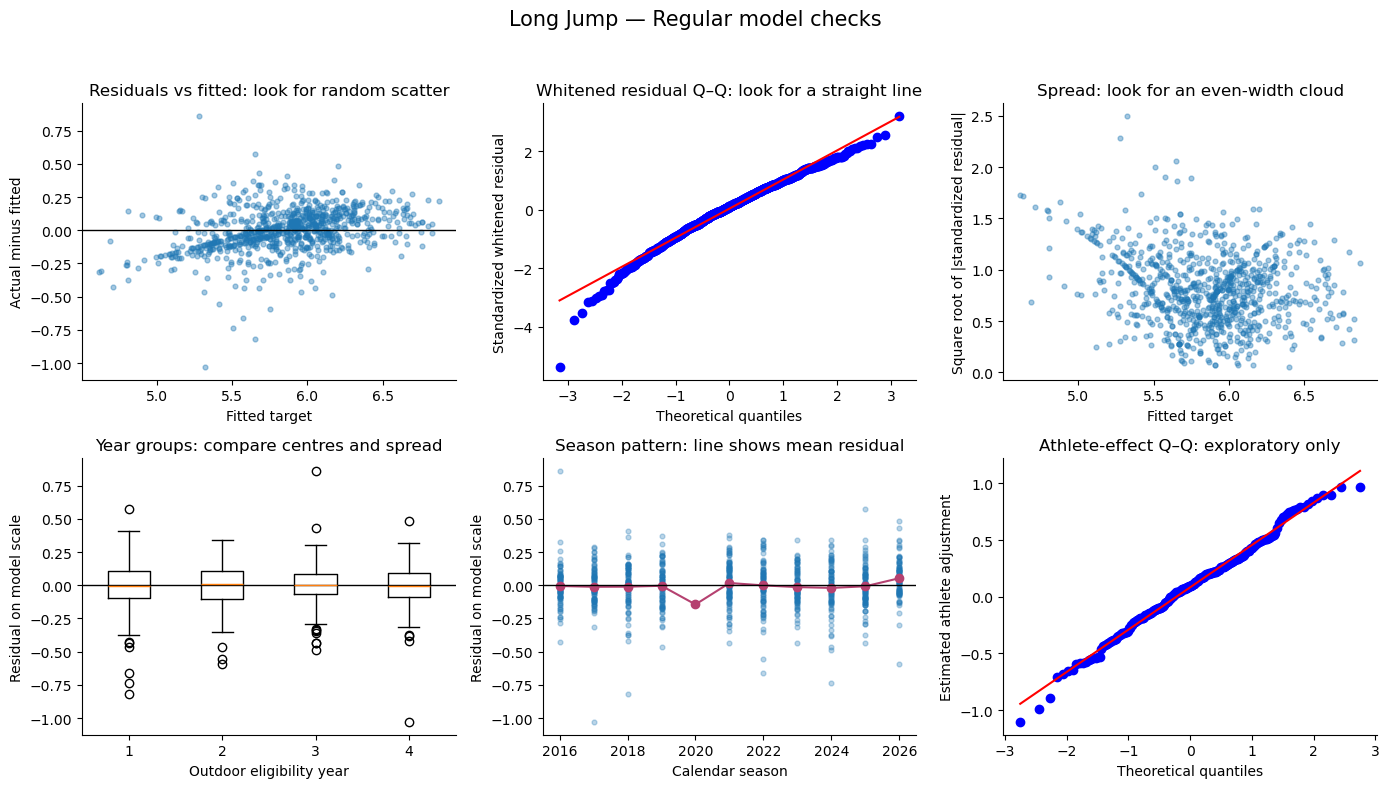

,Diagnostic,Value
0,QQ correlation,0.990298
1,Whitened residual skew,-0.591758
2,Whitened excess kurtosis,1.240237
3,Largest absolute standardized conditional resi...,6.239601
4,Conditional residual SD: largest year / smalle...,1.182327
5,Adjacent observed-season residual correlation,-0.47495
6,Within-athlete residual pairs,401
7,Athlete variance,0.168521
8,Residual variance,0.048851
9,Converged,True


Five largest standardized conditional residuals (flags for inspection, not deletion rules):


,athlete,school,season,outdoor_eligibility_year,best_performance,residual_target,standardized_conditional_residual,source_url
697,"McCoy, Jazmin",Nebraska,2017,4,4.29,-1.0313,-6.2396,https://www.tfrrs.org/results/50133/3055322/Pa...
696,"McCoy, Jazmin",Nebraska,2016,3,6.14,0.8614,5.2103,https://www.tfrrs.org/results/42048/2863272/20...
116,"Marsh, Erin",Duke,2018,1,4.83,-0.8214,-4.2580,https://www.tfrrs.org/results/57034/3509239/AC...
623,"Gatlin, Jada",USC,2024,1,4.77,-0.7364,-4.0053,https://www.tfrrs.org/results/83310/5128035/Tr...
619,"Ganashamoorthy, Hannah",Oregon,2022,1,4.91,-0.6632,-3.6076,https://www.tfrrs.org/results/73106/4462800/Ha...


Sensitivity refits; the main model keeps all included rows:


,Check,Athlete,Rows retained,Fourth-year coefficient,Fourth-year percent change,Largest fixed-coefficient change / original SE,Converged
0,Omit one screened athlete,"McCoy, Jazmin",859,0.21919,NaN,0.27111,True
1,Omit one screened athlete,"Marsh, Erin",857,0.20129,NaN,0.34883,True
2,Omit one screened athlete,"Gatlin, Jada",858,0.20509,NaN,0.33387,True
3,Omit one screened athlete,"Ganashamoorthy, Hannah",858,0.20601,NaN,0.26668,True
4,Omit one screened athlete,"Lott, Falyn",859,0.21418,NaN,0.27387,True
5,Subset: selected best has known wind <= +2,Not a best-legal-mark reselection,804,0.20510,NaN,0.24879,True
6,Subset: previously reviewed eligibility,Different athlete mix; not a full eligibility ...,298,0.28281,NaN,6.33586,True



Long Jump — Log regression
log(best performance) = 1.73612 +0.01757×Year2 +0.02992×Year3 +0.03634×Year4 + athlete adjustment + error


,Comparison,Coefficient,Approx. SE,Approx. lower 95%,Approx. upper 95%,p_value,percent_difference,percent_lower_95,percent_upper_95
0,First-year intercept,1.73612,0.00441,1.72749,1.74476,0.00000,NaN,NaN,NaN
1,Year 2 vs 1,0.01757,0.00423,0.00927,0.02586,0.00003,1.77208,0.93100,2.62017
2,Year 3 vs 1,0.02992,0.00460,0.02091,0.03893,0.00000,3.03709,2.11326,3.96927
3,Year 4 vs 1,0.03634,0.00512,0.02631,0.04637,0.00000,3.70074,2.66615,4.74576


Fourth year vs first: +3.701 percent. Positive means farther.


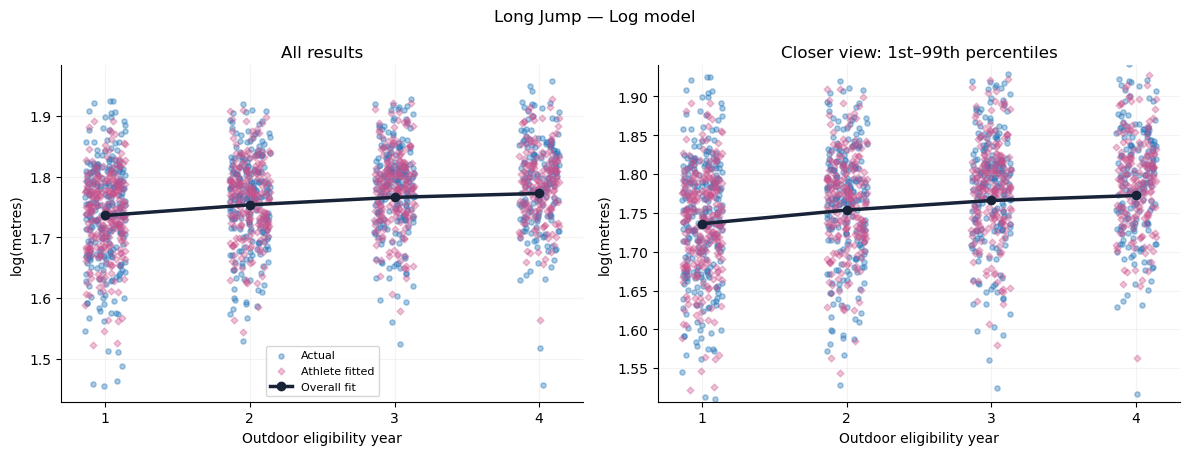

Blue = actual; pink = athlete fitted; dark = overall fit. Hover shows athlete details. Log-chart dots use the fitted log target; tooltip means include back-transformation correction. Long Jump — Log: hover over a point 1.424 1.537 1.650 1.763 1.876 1.989 1 2 3 4 Outdoor eligibility year; higher is better Actual result
Johonnot, Karli
Duke
Season: 2016; eligibility: 4
Actual: 5.680 metres
Fitted mean: 5.734 metres
Athlete ID: athlete_3753694 Fitted result on model scale
Johonnot, Karli
Duke
Season: 2016; eligibility: 4
Actual: 5.680 metres
Fitted mean: 5.734 metres
Athlete ID: athlete_3753694 Actual result
Maslowski, Teddi
Duke
Season: 2016; eligibility: 4
Actual: 5.810 metres
Fitted mean: 5.835 metres
Athlete ID: athlete_3753698 Fitted result on model scale
Maslowski, Teddi
Duke
Season: 2016; eligibility: 4
Actual: 5.810 metres
Fitted mean: 5.835 metres
Athlete ID: athlete_3753698 Actual result
Merkley, Erin
BYU
Season: 2016; eligibility: 4
Actual: 5.270 metres
Fitted mean: 5.412 metres
Athlete ID: athlete_3755585 Fitted result on model scale
Merkley, Erin
BYU
Season: 2016; eligibility: 4
Actual: 5.270 metres
Fitted mean: 5.412 metres
Athlete ID: athlete_3755585 Actual result
Davis, Chalese
South Carolina
Season: 2016; eligibility: 4
Actual: 5.940 metres
Fitted mean: 5.936 metres
Athlete ID: athlete_3756352 Fitted result on model scale
Davis, Chalese
South Carolina
Season: 2016; eligibility: 4
Actual: 5.940 metres
Fitted mean: 5.936 metres
Athlete ID: athlete_3756352 Actual result
Graham, Sarah
South Carolina
Season: 2016; eligibility: 4
Actual: 5.530 metres
Fitted mean: 5.617 metres
Athlete ID: athlete_3756353 Fitted result on model scale
Graham, Sarah
South Carolina
Season: 2016; eligibility: 4
Actual: 5.530 metres
Fitted mean: 5.617 metres
Athlete ID: athlete_3756353 Actual result
Smith, C.J.
Washington
Season: 2016; eligibility: 4
Actual: 5.530 metres
Fitted mean: 5.617 metres
Athlete ID: athlete_4063531 Fitted result on model scale
Smith, C.J.
Washington
Season: 2016; eligibility: 4
Actual: 5.530 metres
Fitted mean: 5.617 metres
Athlete ID: athlete_4063531 Actual result
Storm, Kaci
Iowa State
Season: 2016; eligibility: 3
Actual: 5.640 metres
Fitted mean: 5.695 metres
Athlete ID: athlete_4172512 Fitted result on model scale
Storm, Kaci
Iowa State
Season: 2016; eligibility: 3
Actual: 5.640 metres
Fitted mean: 5.695 metres
Athlete ID: athlete_4172512 Actual result
Saunders, Sha'Keela
Kentucky
Season: 2016; eligibility: 3
Actual: 6.660 metres
Fitted mean: 6.593 metres
Athlete ID: athlete_4177198 Fitted result on model scale
Saunders, Sha'Keela
Kentucky
Season: 2016; eligibility: 3
Actual: 6.660 metres
Fitted mean: 6.593 metres
Athlete ID: athlete_4177198 Actual result
Saunders, Sha'Keela
Kentucky
Season: 2017; eligibility: 4
Actual: 6.790 metres
Fitted mean: 6.636 metres
Athlete ID: athlete_4177198 Fitted result on model scale
Saunders, Sha'Keela
Kentucky
Season: 2017; eligibility: 4
Actual: 6.790 metres
Fitted mean: 6.636 metres
Athlete ID: athlete_4177198 Actual result
Hicks, Traci
Arizona
Season: 2016; eligibility: 4
Actual: 6.060 metres
Fitted mean: 6.028 metres
Athlete ID: athlete_4190677 Fitted result on model scale
Hicks, Traci
Arizona
Season: 2016; eligibility: 4
Actual: 6.060 metres
Fitted mean: 6.028 metres
Athlete ID: athlete_4190677 Actual result
Pfeiffer, Jenna
Baylor
Season: 2017; eligibility: 4
Actual: 5.440 metres
Fitted mean: 5.546 metres
Athlete ID: athlete_4205917 Fitted result on model scale
Pfeiffer, Jenna
Baylor
Season: 2017; eligibility: 4
Actual: 5.440 metres
Fitted mean: 5.546 metres
Athlete ID: athlete_4205917 Actual result
Sadeiko, Grete
Florida State
Season: 2016; eligibility: 3
Actual: 5.970 metres
Fitted mean: 5.950 metres
Athlete ID: athlete_4210213 Fitted result on model scale
Sadeiko, Grete
Florida State
Season: 2016; eligibility: 3
Actual: 5.970 metres
Fitted mean: 5.950 metres
Athlete ID: athlete_4210213 Actual result
Thompson, Natalie
Texas Tech
Season: 2016; eligibility: 4
Actual: 5.500 me

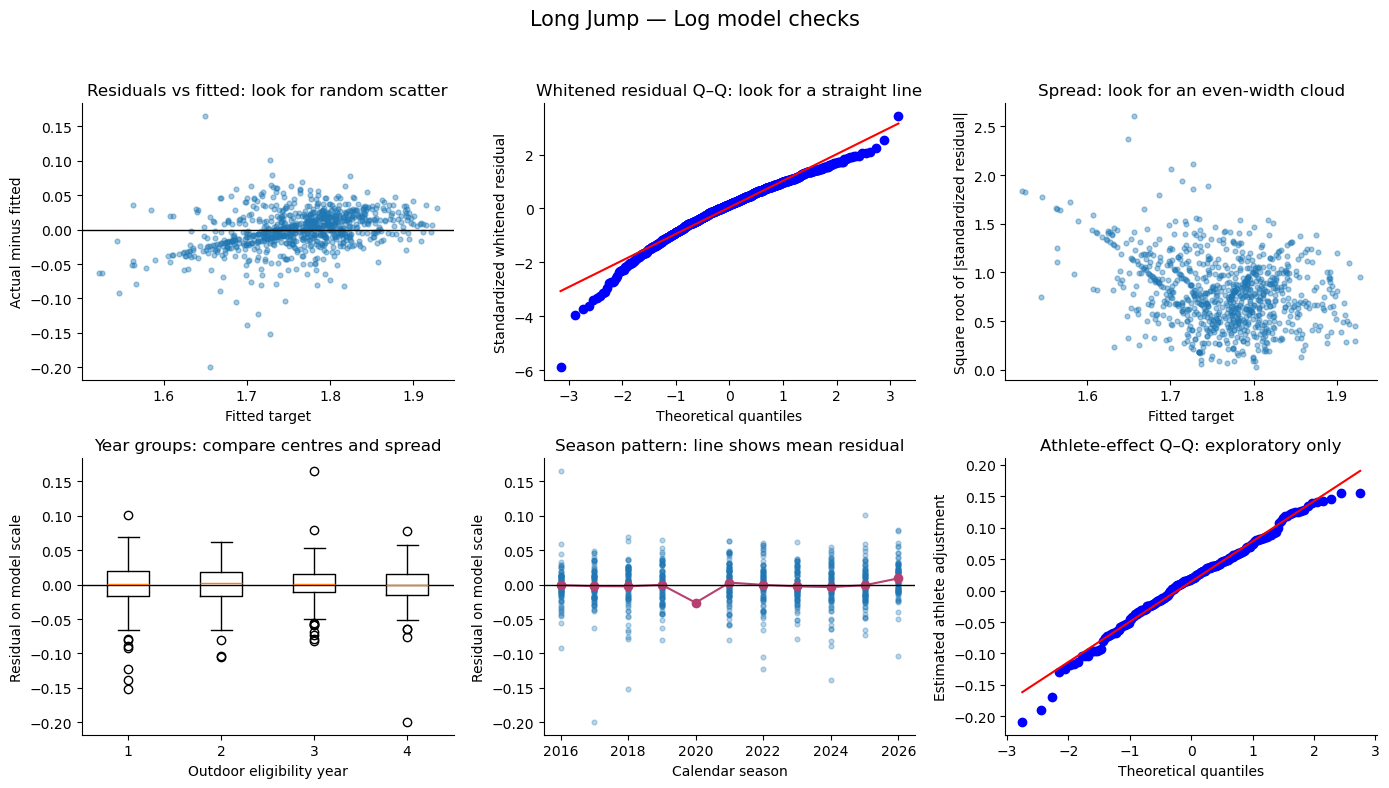

,Diagnostic,Value
0,QQ correlation,0.98135
1,Whitened residual skew,-0.856473
2,Whitened excess kurtosis,2.120914
3,Largest absolute standardized conditional resi...,6.800476
4,Conditional residual SD: largest year / smalle...,1.209437
5,Adjacent observed-season residual correlation,-0.488043
6,Within-athlete residual pairs,401
7,Athlete variance,0.00519
8,Residual variance,0.001539
9,Converged,True


Five largest standardized conditional residuals (flags for inspection, not deletion rules):


,athlete,school,season,outdoor_eligibility_year,best_performance,residual_target,standardized_conditional_residual,source_url
697,"McCoy, Jazmin",Nebraska,2017,4,4.29,-0.1997,-6.8005,https://www.tfrrs.org/results/50133/3055322/Pa...
696,"McCoy, Jazmin",Nebraska,2016,3,6.14,0.1652,5.6236,https://www.tfrrs.org/results/42048/2863272/20...
116,"Marsh, Erin",Duke,2018,1,4.83,-0.1523,-4.4459,https://www.tfrrs.org/results/57034/3509239/AC...
623,"Gatlin, Jada",USC,2024,1,4.77,-0.1382,-4.2344,https://www.tfrrs.org/results/83310/5128035/Tr...
619,"Ganashamoorthy, Hannah",Oregon,2022,1,4.91,-0.1223,-3.7454,https://www.tfrrs.org/results/73106/4462800/Ha...


Sensitivity refits; the main model keeps all included rows:


,Check,Athlete,Rows retained,Fourth-year coefficient,Fourth-year percent change,Largest fixed-coefficient change / original SE,Converged
0,Omit one screened athlete,"McCoy, Jazmin",859,0.03779,3.85125,0.28350,True
1,Omit one screened athlete,"Marsh, Erin",857,0.03446,3.50611,0.36723,True
2,Omit one screened athlete,"Gatlin, Jada",858,0.03514,3.57688,0.35223,True
3,Omit one screened athlete,"Ganashamoorthy, Hannah",858,0.03534,3.59685,0.27911,True
4,Omit one screened athlete,"Lott, Falyn",859,0.03682,3.75096,0.27132,True
5,Subset: selected best has known wind <= +2,Not a best-legal-mark reselection,804,0.03518,3.58107,0.26540,True
6,Subset: previously reviewed eligibility,Different athlete mix; not a full eligibility ...,298,0.05042,5.17161,6.32765,True



Later-season prediction errors in metres (same returning-athlete rows for all methods):


,Method,Test rows,MAE,RMSE,Bias (predicted minus actual)
0,Regular,401,0.2317,0.3112,-0.0048
1,Log,401,0.2332,0.3133,-0.0014
2,Previous season,401,0.2194,0.2987,-0.0556


,test_season,latest_training_season,training_rows,all_test_rows,returning_test_rows
0,2017,2016,89,82,41
1,2018,2017,171,79,48
2,2019,2018,250,86,38
3,2020,2019,336,1,0
4,2021,2020,337,96,35
5,2022,2021,433,83,55
6,2023,2022,516,81,43
7,2024,2023,597,85,45
8,2025,2024,682,89,44
9,2026,2025,771,90,52


Regular MAE minus log MAE = -0.0015 metres. Positive favours log.
Athlete-cluster bootstrap 95% interval: [-0.0024, -0.0006] metres. This resamples held-out errors without refitting models; it is descriptive uncertainty, not a definitive model-selection test.


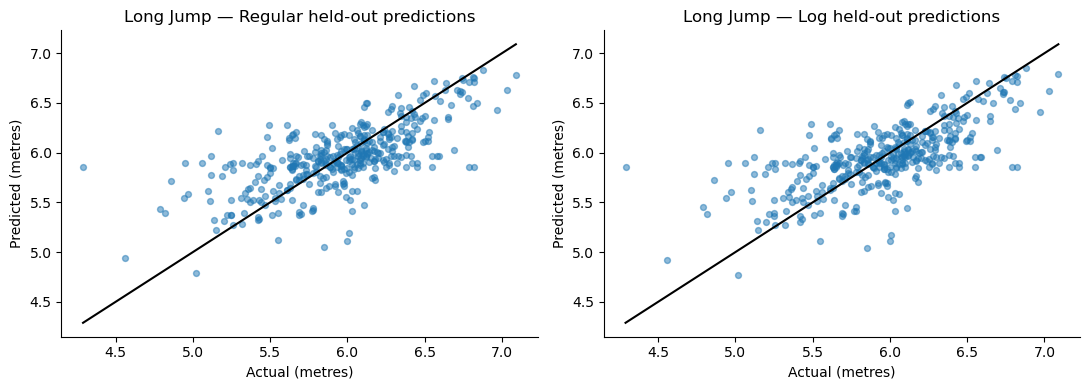

In [13]:
ALL_RESULTS['Long Jump'] = evaluate_event('Long Jump', DATA['Long Jump'])

## Comparing my events

I measure running results in **seconds** and long jump in **meters**, so I cannot directly compare their error sizes.

My table compares **fourth-year athletes with first-year athletes**, while accounting for each athlete’s usual performance level. These differences show a pattern, not proof that moving up a year causes improvement.



In [15]:
summary_rows=[]
check_rows=[]
for event,result in ALL_RESULTS.items():
    unit='metres' if event=='Long Jump' else 'seconds'
    a=result['accuracy'].set_index('Method')
    regular=result['models']['Regular']['fit'];logged=result['models']['Log']['fit']
    summary_rows.append({'Event':event,'Included bests':len(result['data']),'Returning test rows':int(a.loc['Regular','Test rows']),
        'Unit':unit,'Regular: year 4 minus 1':regular['beta'][3], 'Log: year 4 minus 1 (%)':100*np.expm1(logged['beta'][3]),
        'Regular MAE':a.loc['Regular','MAE'],'Log MAE':a.loc['Log','MAE'],'Previous-season MAE':a.loc['Previous season','MAE'],
        'Regular minus log MAE':a.loc['Regular','MAE']-a.loc['Log','MAE'],
        'MAE difference lower 95%':result['delta_ci'][0],'MAE difference upper 95%':result['delta_ci'][1]})
    for label,detail in result['models'].items():
        check_rows.append({'Event':event,'Model':label,**detail['diagnostics']})
SUMMARY=pd.DataFrame(summary_rows)
CHECKS=pd.DataFrame(check_rows)
display(SUMMARY.round(4))
display(CHECKS.round(4))


,Event,Included bests,Returning test rows,Unit,Regular: year 4 minus 1,Log: year 4 minus 1 (%),Regular MAE,Log MAE,Previous-season MAE,Regular minus log MAE,MAE difference lower 95%,MAE difference upper 95%
0,100H,705,314,seconds,-0.5520,-3.6053,0.4411,0.4292,0.4332,0.0118,0.0039,0.0204
1,400H,501,229,seconds,-1.8050,-2.9218,1.6624,1.6591,1.4871,0.0033,-0.0050,0.0135
2,400m,984,411,seconds,-0.8330,-1.5192,1.1841,1.1830,1.1568,0.0011,-0.0014,0.0037
3,Long Jump,861,401,metres,0.2114,3.7007,0.2317,0.2332,0.2194,-0.0015,-0.0024,-0.0006


,Event,Model,QQ correlation,Whitened residual skew,Whitened excess kurtosis,Largest absolute standardized conditional residual,Conditional residual SD: largest year / smallest year,Adjacent observed-season residual correlation,Within-athlete residual pairs,Athlete variance,Residual variance,Converged
0,100H,Regular,0.7735,9.1001,159.8110,18.8264,2.4964,-0.3362,314,0.4389,0.8064,True
1,100H,Log,0.8484,5.7472,84.2247,16.5001,2.0797,-0.4912,314,0.0027,0.0020,True
2,400H,Regular,0.9674,1.2167,4.8123,7.1331,1.3242,-0.4385,229,8.4339,2.6774,True
3,400H,Log,0.9768,0.9510,3.3301,6.5566,1.2606,-0.4380,229,0.0023,0.0007,True
4,400m,Regular,0.9853,0.7277,1.3831,6.0839,1.2042,-0.5014,411,6.7904,1.3682,True
5,400m,Log,0.9898,0.5832,0.9862,5.7667,1.1874,-0.4900,411,0.0021,0.0004,True
6,Long Jump,Regular,0.9903,-0.5918,1.2402,6.2396,1.1823,-0.4749,401,0.1685,0.0489,True
7,Long Jump,Log,0.9814,-0.8565,2.1209,6.8005,1.2094,-0.4880,401,0.0052,0.0015,True


## What my checks tell me

I use the charts and model checks together to look for problems. Flagged results need a closer look, but they do not automatically mean my model is wrong.

My models treat each eligibility year separately. I check whether those year differences and each athlete’s usual performance level explain the results well enough. I do not assume improvement follows a straight line.

In [47]:
for event, result in ALL_RESULTS.items():
    print(f"\n{event}")

    for label, detail in result["models"].items():
        checks = detail["diagnostics"]
        sensitivity = detail["sensitivity"]
        messages = []

        if (
            abs(checks["Whitened residual skew"]) > 1
            or checks["Whitened excess kurtosis"] > 3
        ):
            messages.append(
                "My errors have an uneven pattern or some very large values. "
                "I need to be careful when interpreting this model."
            )
        else:
            messages.append(
                "My error pattern looks less unusual, "
                "but I still need to check the charts."
            )

        if checks[
            "Conditional residual SD: largest year / smallest year"
        ] > 2:
            messages.append(
                "My mistakes vary a lot in size across eligibility years."
            )

        if checks[
            "Largest absolute standardized conditional residual"
        ] > 3:
            messages.append(
                "I found an unusual result that needs a closer look."
            )

        screened = sensitivity[
            sensitivity["Check"] == "Omit one screened athlete"
        ]
        biggest_change = screened[
            "Largest fixed-coefficient change / original SE"
        ].max()

        if biggest_change > 0.5:
            messages.append(
                "Removing one of the athletes I checked noticeably "
                "changes some estimates."
            )
        else:
            messages.append(
                "Removing the athletes I checked one at a time "
                "does not greatly change my estimates."
            )

        if detail["fit"]["lambda"] < 1e-6:
            messages.append(
                "This model finds very little difference "
                "in athletes' starting levels."
            )

        print(f"\n{label} model:")
        for message in messages:
            print(f"- {message}")

    row = SUMMARY[SUMMARY["Event"] == event].iloc[0]

    best = (
        "log"
        if row["Log MAE"] < row["Regular MAE"]
        else "regular"
    )

    print(
        f"\nMy {best} model has the lower average prediction error."
    )
    print(
        "Using the previous season's result gives an average error of "
        f"{row['Previous-season MAE']:.3f} {row['Unit']}."
    )

    if (
        row["MAE difference lower 95%"] <= 0
        <= row["MAE difference upper 95%"]
    ):
        print(
            "The difference is uncertain, so I cannot clearly say "
            "one model predicts better."
        )

    if min(row["Regular MAE"], row["Log MAE"]) >= row[
        "Previous-season MAE"
    ]:
        print(
            "Simply using last season's result predicts better "
            "or equally well on average."
        )

    print("These findings show patterns, not what causes improvement.")

    if event == "100H":
        print("I used my previously reviewed 100H data.")
    else:
        print(
            "I still need to finish checking athlete identities "
            "and eligibility years for this event."
        )


100H

Regular model:
- My errors have an uneven pattern or some very large values. I need to be careful when interpreting this model.
- My mistakes vary a lot in size across eligibility years.
- I found an unusual result that needs a closer look.
- Removing one of the athletes I checked noticeably changes some estimates.

Log model:
- My errors have an uneven pattern or some very large values. I need to be careful when interpreting this model.
- My mistakes vary a lot in size across eligibility years.
- I found an unusual result that needs a closer look.
- Removing one of the athletes I checked noticeably changes some estimates.

My log model has the lower average prediction error.
Using the previous season's result gives an average error of 0.433 seconds.
These findings show patterns, not what causes improvement.
I used my previously reviewed 100H data.

400H

Regular model:
- My errors have an uneven pattern or some very large values. I need to be careful when interpreting this mode

## What I found

My models suggest that fourth-year athletes generally perform better than first-year athletes:

| Event | Regular model | Log model |
|---|---|---|
| 100H | About **0.55 seconds faster** | About **3.61% faster** |
| 400H | About **1.81 seconds faster** | About **2.92% faster** |
| 400m | About **0.83 seconds faster** | About **1.52% faster** |
| Long jump | About **0.21 meters farther** | About **3.70% farther** |

These results show a pattern. They do **not prove that moving up an eligibility year causes improvement**.

### How well my models worked

- **100H:** the log model predicts slightly better, but both models struggle with unusual results, including the **32.80-second time**.
- **400H:** the log model improves the error pattern somewhat, but large mistakes remain.
- **400m:** the error patterns look better than 100H and 400H. The models predict almost equally well.
- **Long jump:** the regular model has slightly better error patterns and prediction accuracy.

For **400H, 400m, and long jump**, simply using an athlete’s previous-season result predicts better on average than either regression.

### My conclusion

All eight models ran successfully, but that does not mean they fit the data well. I need to be especially careful with **100H and 400H** because unusual results affect the findings.

I kept those results in my main analysis. I also need to finish checking athlete names and eligibility years for the additional events. **My findings are preliminary.**

## My conclusion and limits

My models help me describe how athletes’ best performances differ by eligibility year. To judge them, I look at **their mistakes, how unusual results affect them, and how well they predict later seasons**. Using log values does not automatically make a model better.

My models account for the same athlete appearing in several seasons. However, differences between years could also reflect **training, injuries, race conditions, missing meets, or which athletes keep competing**. I have not separately modeled school, conference, wind, or calendar-season effects.

I checked that each athlete has only one selected best result per season. However, **I have not checked every result and eligibility year against original meet results and team rosters**. My findings for the additional events are still preliminary. Excluded cases and source links are included in the notebook.

## My data and methods

The notebook includes my data, models, error checks, and prediction results. **No separate data download is needed.**

I use Python with NumPy, pandas, SciPy, and Matplotlib. My models compare eligibility years while allowing each athlete to have a different starting level. The fitting code is included so the analysis can be rerun.

Method references:

- [NIST: checking model assumptions](https://itl.nist.gov/div898/handbook/pri/section2/pri245.htm)
- [statsmodels: mixed-effects models](https://www.statsmodels.org/stable/mixed_linear.html)

These sources explain the methods. My notebook uses its own fitting code, rather than the statsmodels package.

In [20]:
display(pd.DataFrame(PAYLOAD['manifest']))
print('Source snapshot hashes record the exact input files; source URLs may change after retrieval.')

,event,url,sha256,source_rows,retrieved
0,400H,https://raw.githubusercontent.com/jaiamcgee/co...,feccc1eab1385690adb3a961a84ad5aa2884f22280ceae...,2711,2026-11-04
1,400m,https://raw.githubusercontent.com/jaiamcgee/co...,07e2695df9ea5c28c493feaff87aec7b69d4da18aaf04e...,3263,2026-11-04
2,Long Jump,https://raw.githubusercontent.com/jaiamcgee/co...,8559fca208052a2bcd5656992a182a6225b69374221abb...,3156,2026-11-04
3,100H,Earlier reviewed 100H_best_time_per_season.csv,23d08171dd734add6ca19edc9bc239ac22a445abfa4243...,705,Retained from earlier review


Source snapshot hashes record the exact input files; source URLs may change after retrieval.
